# # 05 — MLP trên MNIST: tự cài đặt (`src/mlp.py`) vs. thư viện (`scikit-learn`)
#
# Notebook này phục vụ phần **MLP (Multi-Layer Perceptron)** của đồ án giữa kỳ Nhận dạng mẫu.
# Mục tiêu không chỉ là "chạy được", mà là **đối chiếu có kiểm chứng** giữa một MLP viết tay
# bằng NumPy và một MLP của thư viện, kèm theo **phân tích định lượng ảnh hưởng của siêu tham số**.
#
# ## Câu hỏi nghiên cứu
#
# | # | Câu hỏi | Phần trả lời |
# |---|---------|--------------|
# | RQ1 | Backprop tự cài đặt có **đúng** so với thư viện không? (sai số số học bao nhiêu?) | §6 |
# | RQ2 | Với cùng kiến trúc & cùng bộ tối ưu SGD, hai cách cài đặt cho **chất lượng** và **thời gian** khác nhau thế nào? | §5, §7 |
# | RQ3 | Hai mô hình **sai giống nhau hay khác nhau**? Chênh lệch có ý nghĩa thống kê không? | §8 |
# | RQ4 | **Siêu tham số** (learning rate, số lớp/nơ-ron, số vòng lặp, batch size, L2, số cây) ảnh hưởng ra sao? | §9 |
#
# ## Cấu hình môi trường
#
# * Python 3.14, NumPy 2.5.4, scikit-learn 1.9.1, Matplotlib 3.11.2, seed = 42 (`src/config.py`).
# * Toàn bộ hình được lưu vào `results/figures/05_mlp_*.png`, số liệu tổng hợp vào `results/logs/05_mlp_summary.json`
#   để dùng trực tiếp trong báo cáo.
# * Dữ liệu: 60 000 ảnh train (chia 54 000 train / 6 000 validation) + 10 000 ảnh test.
#   Các thí nghiệm **quét siêu tham số** dùng tập con stratified 12 000 mẫu để chạy trong thời gian hợp lý;
#   thí nghiệm **chính** (so sánh 2 thư viện) dùng đủ 54 000 mẫu.

# ## 1. Thiết lập môi trường

In [1]:
import json
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier as SklearnMLP

warnings.filterwarnings("ignore")


def _find_root() -> Path:
    """Tìm thư mục gốc repo (nơi có package src/) để import được dù kernel chạy ở đâu."""
    p = Path.cwd()
    while not (p / "src").is_dir() and p != p.parent:
        p = p.parent
    return p


ROOT = _find_root()
sys.path.insert(0, str(ROOT))

from src.config import FIG_DIR, LOG_DIR, SEED
from src.data import load_prepared_mnist
from src.metrics import classification_metrics
from src.models.mlp import MLPClassifier
from src.utils import set_seed

set_seed(SEED)
FIG_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 160,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.axisbelow": True,
})

CUSTOM_COLOR = "#1f77b4"   # MLP tự cài đặt
SKLEARN_COLOR = "#d62728"  # MLP của sklearn

# Toàn bộ siêu tham số "chuẩn" của notebook nằm ở đây để dễ tái lập / đổi cấu hình.
CFG = dict(
    hidden=(256, 128),
    lr=0.08,
    epochs=20,
    batch=256,
    l2=1e-4,
    n_sub=12_000,      # kích thước tập con cho các thí nghiệm quét
    sub_epochs=8,      # số epoch mặc định cho các thí nghiệm quét
    probe_size=10_000, # số mẫu cố định để đo loss/accuracy train mỗi epoch
)

print(f"Repo root      : {ROOT}")
print(f"NumPy          : {np.__version__}")
print(f"SEED           : {SEED}")
print(f"Cấu hình chính : {CFG}")

Repo root      : D:\midterm_pattern_recognition\mnist-pattern-recognition
NumPy          : 2.5.4
SEED           : 42
Cấu hình chính : {'hidden': (256, 128), 'lr': 0.08, 'epochs': 20, 'batch': 256, 'l2': 0.0001, 'n_sub': 12000, 'sub_epochs': 8, 'probe_size': 10000}


# ### Hàm tiện ích dùng chung
#
# * `savefig` — lưu hình vào `results/figures/` với tiền tố `05_mlp_`.
# * `show_table` — in bảng căn cột (không phụ thuộc pandas).
# * `ce_from_proba` — cross-entropy trung bình từ xác suất dự đoán (dùng chung cho cả 2 mô hình
#   để **so sánh loss trên cùng một thang đo**).

In [2]:
def savefig(fig, name: str) -> Path:
    path = FIG_DIR / f"05_mlp_{name}.png"
    fig.savefig(path, dpi=160, bbox_inches="tight")
    return path


def show_table(headers, rows, title: str = "") -> None:
    body = [
        [f"{v:.4f}" if isinstance(v, (float, np.floating)) else str(v) for v in row]
        for row in rows
    ]
    widths = []
    for i, head in enumerate(headers):
        widths.append(max([len(head)] + [len(r[i]) for r in body]))
    if title:
        print(title)
    header_line = "  ".join(h.rjust(w) for h, w in zip(headers, widths))
    print(header_line)
    print("-" * len(header_line))
    for row in body:
        print("  ".join(c.rjust(w) for c, w in zip(row, widths)))
    print()


def ce_from_proba(proba: np.ndarray, y_idx: np.ndarray) -> float:
    return float(-np.mean(np.log(proba[np.arange(len(y_idx)), y_idx] + 1e-12)))


def count_params(weights, biases) -> int:
    return int(sum(w.size for w in weights) + sum(b.size for b in biases))

# > **Ghi chú kỹ thuật:** notebook tự vẽ hình thay vì dùng `src/plots.py`, vì module đó gọi
# > `matplotlib.use("Agg")` ngay lúc import (backend không tương tác) nên hình sẽ không hiển thị
# > trực tiếp trong Jupyter. Các hàm trong `src/plots.py` vẫn dùng được cho script/hình lưu file.

# ## 2. Dữ liệu và cách chia tập
#
# MNIST đã được tải sẵn ở `data/raw/` và tiền xử lý trong `src/data.py`: mỗi ảnh 28×28 được
# **flatten** thành vector 784 chiều và **chuẩn hoá** về `[0, 1]`.
#
# Cách chia:
#
# ```
# train gốc (60 000) ──┬─ 54 000  → huấn luyện
#                      └─  6 000  → validation (chọn siêu tham số)
# test (10 000)       →  chỉ dùng để báo cáo kết quả cuối (không dùng để chọn mô hình)
# ```
#
# Tách riêng tập validation giúp việc quét siêu tham số ở §9 **không bị rò rỉ** sang tập test.

Bảng 2.1 — Các tập dữ liệu
               Tập  Số mẫu  Kích thước mỗi mẫu  Số lớp           Dùng cho
-------------------------------------------------------------------------
train (X_tr, y_tr)   54000                 784      10         huấn luyện
        validation    6000                 784      10  chọn siêu tham số
              test   10000                 784      10       báo cáo cuối
         train_sub   12000                 784      10    thí nghiệm quét

Pixel: min=0.0, max=1.0, dtype=float32
Phân bố nhãn train: min=4879, max=6068 (lệch 1189 mẫu)


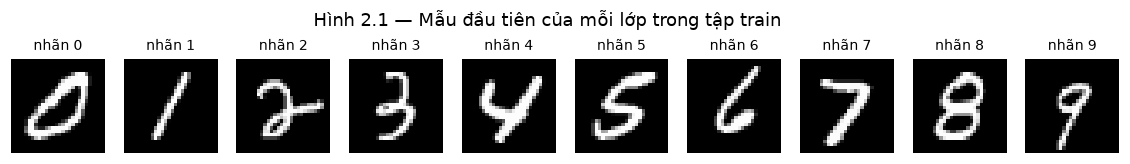

In [3]:
X_all, y_all, X_test, y_test = load_prepared_mnist()

X_tr, X_val, y_tr, y_val = train_test_split(
    X_all, y_all, test_size=0.1, stratify=y_all, random_state=SEED
)
X_sub, _, y_sub, _ = train_test_split(
    X_tr, y_tr, train_size=CFG["n_sub"], stratify=y_tr, random_state=SEED
)

show_table(
    ["Tập", "Số mẫu", "Kích thước mỗi mẫu", "Số lớp", "Dùng cho"],
    [
        ["train (X_tr, y_tr)", len(X_tr), X_tr.shape[1], len(np.unique(y_tr)), "huấn luyện"],
        ["validation", len(X_val), X_val.shape[1], len(np.unique(y_val)), "chọn siêu tham số"],
        ["test", len(X_test), X_test.shape[1], len(np.unique(y_test)), "báo cáo cuối"],
        ["train_sub", len(X_sub), X_sub.shape[1], len(np.unique(y_sub)), "thí nghiệm quét"],
    ],
    "Bảng 2.1 — Các tập dữ liệu",
)

counts = np.bincount(y_tr, minlength=10)
print(f"Pixel: min={X_tr.min():.1f}, max={X_tr.max():.1f}, dtype={X_tr.dtype}")
print(f"Phân bố nhãn train: min={counts.min()}, max={counts.max()} (lệch {counts.max() - counts.min()} mẫu)")

fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for digit in range(10):
    idx = np.flatnonzero(y_tr == digit)[0]
    axes[digit].imshow(X_tr[idx].reshape(28, 28), cmap="gray")
    axes[digit].set_title(f"nhãn {digit}", fontsize=9)
    axes[digit].axis("off")
fig.suptitle("Hình 2.1 — Mẫu đầu tiên của mỗi lớp trong tập train")
savefig(fig, "01_samples")
plt.show()

# ## 3. Cơ sở toán học của MLP tự cài đặt
#
# Kiến trúc trong `src/mlp.py` là mạng truyền thẳng đầy đủ với:
#
# * **Lan truyền tiến (forward)**: lớp ẩn dùng ReLU, lớp ra dùng Softmax:
#   $$a^{(0)} = x,\qquad z^{(l)} = a^{(l-1)}W^{(l)} + b^{(l)},\qquad a^{(l)} = \max(0, z^{(l)}),$$
#   $$p = \operatorname{softmax}(z^{(L)}) = \frac{e^{z_k}}{\sum_j e^{z_j}}.$$
# * **Hàm mất mát**: cross-entropy + chuẩn hoá L2
#   $$\mathcal{L} = -\frac{1}{B}\sum_{i=1}^{B}\log p_{i,y_i} + \frac{\lambda}{2}\sum_{l}\lVert W^{(l)}\rVert_F^2 .$$
# * **Lan truyền ngược (backward)**: nhờ đạo hàm của softmax + cross-entropy triệt tiêu nhau,
#   delta ở lớp ra rất gọn: $\delta^{(L)} = p - \text{onehot}(y)$, sau đó
#   $$\delta^{(l)} = \big(\delta^{(l+1)} W^{(l+1)\top}\big)\odot\mathbb{1}[z^{(l)}>0],$$
#   $$\nabla_{W^{(l)}} = a^{(l-1)\top}\delta^{(l)} + \lambda W^{(l)},\qquad \nabla_{b^{(l)}} = \sum_i \delta^{(l)}_i .$$
# * **Cập nhật SGD** theo minibatch: $W \leftarrow W - \eta\nabla_W \mathcal{L}$.
# * **Khởi tạo He**: $W \sim \mathcal{N}\!\left(0, \sqrt{2/n_{in}}\right)$ — phù hợp với ReLU.
#
# Một điểm **rất dễ sai** khi so sánh với thư viện là **quy ước chuẩn hoá của số hạng L2**.
#
# * Trong `src/mlp.py`: gradient có `+ l2 * W`, **không** chia cho batch size.
# * Trong scikit-learn (`_compute_loss_grad`): `coef_grads = (Aᵀ·δ + alpha·W) / B`, tức là **chia cho B**.
#
# Suy ra ánh xạ tương đương (sẽ được **kiểm chứng bằng số** ở §6):
#
# $$\alpha_{\text{sklearn}} = \lambda \times B$$
#
# Với $\lambda = 10^{-4}$ và $B = 256$ thì $\alpha = 0.0256$, **lớn hơn 256 lần** giá trị mặc định
# `alpha=1e-4` của sklearn. Nếu bỏ qua chi tiết này, phép so sánh sẽ không công bằng.

# ## 4. Lớp bọc `TrackingMLP`: đo chỉ số theo từng epoch
#
# `MLPClassifier` trong `src/mlp.py` chỉ lưu `history_` (loss train). Để vẽ đường cong
# accuracy/loss theo epoch, notebook định nghĩa `TrackingMLP` **kế thừa nguyên vẹn**
# `_init_para`, `_forward`, `_backward`, `_loss`, `predict` — chỉ thay vòng lặp `fit`
# bằng một vòng lặp y hệt nhưng có đo thêm chỉ số sau mỗi epoch.
#
# * Không thay đổi luồng sinh số ngẫu nhiên của mô hình gốc (dùng RNG riêng cho tập probe),
#   nên **trọng số sau huấn luyện trùng khít** với `MLPClassifier` gốc — được kiểm chứng ngay bên dưới.

In [4]:
class TrackingMLP(MLPClassifier):
    """MLPClassifier + ghi lại loss/accuracy theo epoch (giữ nguyên logic huấn luyện gốc)."""

    def fit(self, X, y, X_val=None, y_val=None):
        X = np.asarray(X, dtype=np.float64)
        self.classes_, y_idx = np.unique(y, return_inverse=True)
        rng = np.random.default_rng(self.seed)
        self._init_para(X.shape[1], len(self.classes_), rng)
        self.history_ = []

        n = len(X)
        probe_rng = np.random.default_rng(self.seed + 991)  # RNG riêng: không làm lệch luồng train
        probe = probe_rng.choice(n, size=min(CFG["probe_size"], n), replace=False)
        z_val = None if X_val is None else np.searchsorted(self.classes_, y_val)

        self.probe_loss_, self.train_acc_, self.val_loss_, self.val_acc_ = [], [], [], []
        self.epoch_time_ = []

        for _ in range(self.epochs):
            t0 = time.perf_counter()
            perm = rng.permutation(n)
            for start in range(0, n, self.batch_size):
                idx = perm[start : start + self.batch_size]
                self._backward(X[idx], y_idx[idx])
            self.epoch_time_.append(time.perf_counter() - t0)

            # Loss ghi lại là cross-entropy thuần (không cộng hạng L2) để so sánh được với sklearn
            proba_probe = self._forward(X[probe])[1]
            self.probe_loss_.append(ce_from_proba(proba_probe, y_idx[probe]))
            self.train_acc_.append(float(np.mean(np.argmax(proba_probe, 1) == y_idx[probe])))
            if X_val is not None:
                proba_val = self._forward(np.asarray(X_val, dtype=np.float64))[1]
                self.val_loss_.append(ce_from_proba(proba_val, z_val))
                self.val_acc_.append(float(np.mean(np.argmax(proba_val, 1) == z_val)))
        self.history_ = self.probe_loss_
        return self


# --- Kiểm chứng: lớp bọc không làm thay đổi kết quả so với MLPClassifier gốc ---
kw = dict(hidden_units=(64, 32), learning_rate=0.08, epochs=3, batch_size=256, l2=1e-4, seed=SEED)
plain = MLPClassifier(**kw).fit(X_sub, y_sub)
wrapped = TrackingMLP(**kw).fit(X_sub, y_sub)

max_dw = max(float(np.abs(a - b).max()) for a, b in zip(plain.weights_, wrapped.weights_))
print(f"max |ΔW| giữa MLPClassifier gốc và TrackingMLP : {max_dw:.3e}")
print(f"Số mẫu test dự đoán khác nhau                 : {int(np.sum(plain.predict(X_test) != wrapped.predict(X_test)))}")
print(f"Accuracy 3 epoch trên tập con                 : {plain.score(X_test, y_test):.4f}")

max |ΔW| giữa MLPClassifier gốc và TrackingMLP : 0.000e+00
Số mẫu test dự đoán khác nhau                 : 0
Accuracy 3 epoch trên tập con                 : 0.8905


# `max |ΔW| = 0` và 0 mẫu test bị dự đoán khác nhau ⇒ **lớp bọc trung tính**,
# mọi số liệu bên dưới phản ánh đúng thuật toán trong `src/mlp.py`.

# ## 5. Huấn luyện chính: cùng một "hợp đồng" siêu tham số
#
# Để phép so sánh có ý nghĩa, hai mô hình được cấu hình **tương đương từng thành phần**:
#
# | Thành phần | `src/mlp.py` | scikit-learn |
# |---|---|---|
# | Kiến trúc | `hidden_units=(256,128)` | `hidden_layer_sizes=(256,128)` |
# | Kích hoạt | ReLU + Softmax | `activation='relu'`, `out_activation_='softmax'` (log-loss) |
# | Bộ tối ưu | SGD thuần | `solver='sgd'`, `learning_rate='constant'`, `momentum=0` |
# | Learning rate | `learning_rate=0.08` | `learning_rate_init=0.08` |
# | Minibatch | `batch_size=256` | `batch_size=256`, `shuffle=True` |
# | Chuẩn hoá L2 | `l2=1e-4` | `alpha = 1e-4 × 256 = 0.0256` (xem §3, §6) |
# | Số epoch | `epochs=20` | 20 vòng `partial_fit` (mỗi lần đúng 1 epoch) |
# | Khởi tạo | He normal $\mathcal{N}(0,\sqrt{2/n_{in}})$ | Glorot uniform (mặc định) |
# | Dừng sớm | không | `tol=0`, `early_stopping=False` để chạy đủ 20 epoch |
#
# Hai điểm khác biệt **không thể** san bằng: hàm khởi tạo (sklearn không hỗ trợ He normal) và
# thứ tự xáo trộn dữ liệu. Ảnh hưởng của chúng được **tách riêng** ở §6 bằng thí nghiệm
# "cùng điểm khởi tạo".

In [5]:
def fit_sklearn_epochwise(X, y, X_val, y_val, probe, epochs, **sk_kw):
    """Huấn luyện sklearn MLP từng epoch bằng partial_fit và ghi chỉ số giống TrackingMLP."""
    model = SklearnMLP(max_iter=1, **sk_kw)
    classes = np.unique(y)
    hist = dict(probe_loss=[], train_acc=[], val_loss=[], val_acc=[], epoch_time=[])
    for _ in range(epochs):
        t0 = time.perf_counter()
        model.partial_fit(X, y, classes=classes)  # mỗi partial_fit = đúng 1 epoch
        hist["epoch_time"].append(time.perf_counter() - t0)

        proba_probe = model.predict_proba(X[probe])
        hist["probe_loss"].append(ce_from_proba(proba_probe, y[probe]))
        hist["train_acc"].append(float(np.mean(np.argmax(proba_probe, 1) == y[probe])))
        proba_val = model.predict_proba(X_val)
        hist["val_loss"].append(ce_from_proba(proba_val, y_val))
        hist["val_acc"].append(float(np.mean(np.argmax(proba_val, 1) == y_val)))
    return model, hist


def sk_kwargs(hidden=None, lr=None, batch=None, l2=None, seed=SEED):
    """Ánh xạ siêu tham số của src/mlp.py sang sklearn (alpha = l2 × batch_size)."""
    hidden = CFG["hidden"] if hidden is None else tuple(hidden)
    lr = CFG["lr"] if lr is None else lr
    batch = CFG["batch"] if batch is None else batch
    l2 = CFG["l2"] if l2 is None else l2
    return dict(
        hidden_layer_sizes=hidden,
        solver="sgd",
        learning_rate="constant",
        learning_rate_init=lr,
        batch_size=batch,
        alpha=l2 * batch,
        momentum=0.0,
        nesterovs_momentum=False,
        shuffle=True,
        tol=0.0,
        early_stopping=False,
        random_state=seed,
    )


probe_tr = np.random.default_rng(SEED + 991).choice(
    len(X_tr), size=min(CFG["probe_size"], len(X_tr)), replace=False
)
probe_sub = np.random.default_rng(SEED + 991).choice(
    len(X_sub), size=min(CFG["probe_size"], len(X_sub)), replace=False
)

t0 = time.perf_counter()
mlp_custom = TrackingMLP(
    hidden_units=CFG["hidden"], learning_rate=CFG["lr"], epochs=CFG["epochs"],
    batch_size=CFG["batch"], l2=CFG["l2"], seed=SEED,
).fit(X_tr, y_tr, X_val=X_val, y_val=y_val)
time_custom_train = time.perf_counter() - t0

t0 = time.perf_counter()
mlp_sk, hist_sk = fit_sklearn_epochwise(
    X_tr, y_tr, X_val, y_val, probe_tr, CFG["epochs"], **sk_kwargs()
)
time_sk_train = time.perf_counter() - t0

show_table(
    ["Mô hình", "Số epoch thực tế", "Thời gian train (s)", "s/epoch", "Val acc cuối", "Val loss cuối"],
    [
        ["Tự cài đặt", len(mlp_custom.probe_loss_), time_custom_train,
         time_custom_train / len(mlp_custom.probe_loss_), mlp_custom.val_acc_[-1], mlp_custom.val_loss_[-1]],
        ["sklearn", len(hist_sk["val_acc"]), time_sk_train,
         time_sk_train / len(hist_sk["val_acc"]), hist_sk["val_acc"][-1], hist_sk["val_loss"][-1]],
    ],
    f"Bảng 5.1 — Thời gian huấn luyện ({len(X_tr):,} mẫu, {CFG['epochs']} epoch)",
)

Bảng 5.1 — Thời gian huấn luyện (54,000 mẫu, 20 epoch)
   Mô hình  Số epoch thực tế  Thời gian train (s)  s/epoch  Val acc cuối  Val loss cuối
---------------------------------------------------------------------------------------
Tự cài đặt                20              87.2653   4.3633        0.9717         0.0938
   sklearn                20              47.1596   2.3580        0.9722         0.1004



# ## 6. RQ1 — Kiểm chứng backprop: hai mô hình có học **cùng một hàm** không?
#
# So sánh accuracy cuối cùng không đủ để kết luận "code tự viết đúng", vì hai mô hình có thể
# hội tụ về hai nghiệm khác nhau nhưng cùng chất lượng. Thí nghiệm dưới đây cô lập **sai số
# số học** của phép lan truyền ngược:
#
# 1. Lấy **cùng một bộ trọng số** (khởi tạo Glorot của sklearn) nạp vào MLP tự cài đặt.
# 2. Chạy **full-batch gradient descent** (batch = toàn bộ dữ liệu) nên không có yếu tố ngẫu nhiên.
# 3. Sau mỗi bước, so sánh `max |ΔW|` giữa hai mô hình và loss cross-entropy.
#
# Nếu công thức đạo hàm đúng, hai quỹ đạo phải trùng nhau tới mức sai số dấu phẩy động.

In [6]:
N_TINY = 5_000
X_tiny, y_tiny = X_tr[:N_TINY], y_tr[:N_TINY]
hidden_tiny = (32, 16)

sk_ref = SklearnMLP(
    hidden_layer_sizes=hidden_tiny, solver="sgd", learning_rate="constant",
    learning_rate_init=0.1, batch_size=N_TINY, alpha=0.0, momentum=0.0,
    nesterovs_momentum=False, shuffle=False, tol=0.0, random_state=0, max_iter=1,
).fit(X_tiny, y_tiny)

custom_ref = MLPClassifier(
    hidden_units=hidden_tiny, learning_rate=0.1, epochs=1,
    batch_size=N_TINY, l2=0.0, seed=0,
)
custom_ref.weights_ = [w.copy() for w in sk_ref.coefs_]
custom_ref.biases_ = [b.copy() for b in sk_ref.intercepts_]
custom_ref.classes_ = np.unique(y_tiny)
idx_tiny = np.searchsorted(custom_ref.classes_, y_tiny)

steps = 6
equiv_rows = []
dw_values = []
for step in range(1, steps + 1):
    custom_ref._backward(X_tiny, idx_tiny)                      # 1 bước GD của code tự viết
    sk_ref.partial_fit(X_tiny, y_tiny, classes=np.arange(10))    # 1 bước GD của sklearn
    dw = max(float(np.abs(a - b).max()) for a, b in zip(custom_ref.weights_, sk_ref.coefs_))
    loss_cu = ce_from_proba(custom_ref.predict_proba(X_tiny), idx_tiny)
    loss_sk = ce_from_proba(sk_ref.predict_proba(X_tiny), idx_tiny)
    dw_values.append(dw)
    equiv_rows.append([step, loss_cu, loss_sk, f"{abs(loss_cu - loss_sk):.2e}", f"{dw:.2e}"])

show_table(
    ["Bước GD", "Loss tự cài đặt", "Loss sklearn", "|Δloss|", "max|ΔW|"],
    equiv_rows,
    "Bảng 6.1 — Đối chiếu từng bước cập nhật, full-batch, không chuẩn hoá L2 (n=5 000)",
)

Bảng 6.1 — Đối chiếu từng bước cập nhật, full-batch, không chuẩn hoá L2 (n=5 000)
Bước GD  Loss tự cài đặt  Loss sklearn   |Δloss|   max|ΔW|
----------------------------------------------------------
      1           2.3175        2.3175  1.53e-08  2.98e-08
      2           2.3027        2.3027  1.40e-07  2.98e-08
      3           2.2880        2.2880  1.30e-07  2.98e-08
      4           2.2731        2.2731  9.24e-08  2.98e-08
      5           2.2581        2.2581  2.90e-07  2.98e-08
      6           2.2429        2.2429  9.34e-08  2.98e-08



# Cùng phép thử, nhưng **bật chuẩn hoá L2** để kiểm chứng công thức ánh xạ
# $\alpha = \lambda B$ đã nêu ở §3. Nếu dùng `alpha = 1e-4` (giá trị mặc định của sklearn)
# thì trọng số sẽ lệch rõ rệt; với `alpha = 1e-4 × 5000` thì phải trùng khớp.

Bảng 6.2 — Kiểm chứng ánh xạ alpha ↔ l2
      Cấu hình chuẩn hoá của sklearn  alpha  max|ΔW| sau 3 bước (λ = 1e-4)
--------------------------------------------------------------------------
                    Mặc định sklearn   1e-4                       1.42e-05
Khớp với code tự viết: alpha = λ × B    0.5                       2.98e-08



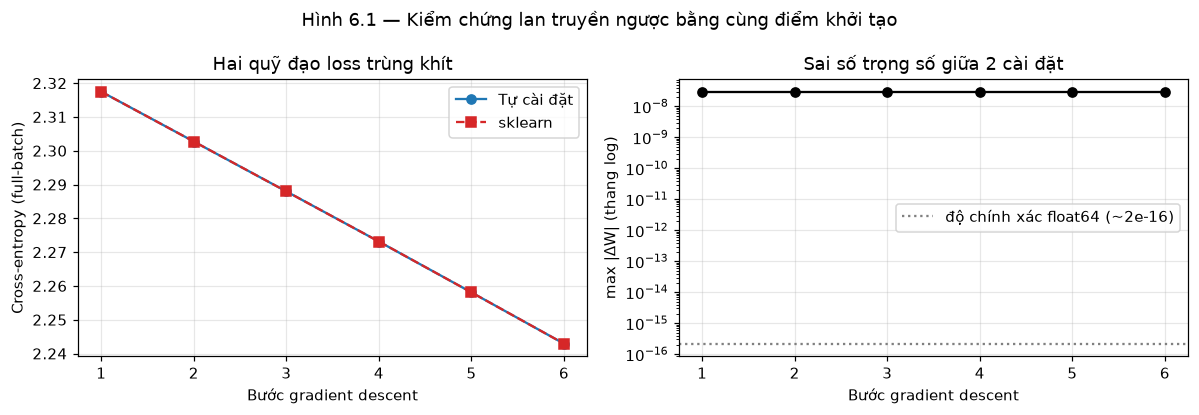

Nhận xét:
  • Sau 6 bước, max|ΔW| = 2.98e-08 → chỉ là nhiễu làm tròn float64/float32.
  • Với alpha khớp (λ×B), sai số 2.98e-08; với alpha mặc định, sai số 1.42e-05 (lệch 476 lần).
  ⇒ Công thức backprop trong src/mlp.py tương đương về mặt toán học với sklearn;
    khác biệt duy nhất khi huấn luyện thật là khởi tạo và thứ tự xáo trộn minibatch.


In [7]:
L2_TINY = 1e-4


def one_step_pair(alpha_sk):
    sk = SklearnMLP(
        hidden_layer_sizes=hidden_tiny, solver="sgd", learning_rate="constant",
        learning_rate_init=0.1, batch_size=N_TINY, alpha=alpha_sk, momentum=0.0,
        nesterovs_momentum=False, shuffle=False, tol=0.0, random_state=0, max_iter=1,
    ).fit(X_tiny, y_tiny)
    cu = MLPClassifier(hidden_units=hidden_tiny, learning_rate=0.1, epochs=1,
                       batch_size=N_TINY, l2=L2_TINY, seed=0)
    cu.weights_ = [w.copy() for w in sk.coefs_]
    cu.biases_ = [b.copy() for b in sk.intercepts_]
    cu.classes_ = np.unique(y_tiny)
    for _ in range(3):
        cu._backward(X_tiny, idx_tiny)
        sk.partial_fit(X_tiny, y_tiny, classes=np.arange(10))
    dw = max(float(np.abs(a - b).max()) for a, b in zip(cu.weights_, sk.coefs_))
    return dw


dw_default = one_step_pair(1e-4)
dw_matched = one_step_pair(L2_TINY * N_TINY)

show_table(
    ["Cấu hình chuẩn hoá của sklearn", "alpha", "max|ΔW| sau 3 bước (λ = 1e-4)"],
    [
        ["Mặc định sklearn", "1e-4", f"{dw_default:.2e}"],
        ["Khớp với code tự viết: alpha = λ × B", f"{L2_TINY * N_TINY:g}", f"{dw_matched:.2e}"],
    ],
    "Bảng 6.2 — Kiểm chứng ánh xạ alpha ↔ l2",
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
loss_cu = [r[1] for r in equiv_rows]
loss_sk = [r[2] for r in equiv_rows]
axes[0].plot(range(1, steps + 1), loss_cu, "o-", color=CUSTOM_COLOR, label="Tự cài đặt")
axes[0].plot(range(1, steps + 1), loss_sk, "s--", color=SKLEARN_COLOR, label="sklearn")
axes[0].set_xlabel("Bước gradient descent")
axes[0].set_ylabel("Cross-entropy (full-batch)")
axes[0].set_title("Hai quỹ đạo loss trùng khít")
axes[0].legend()

dws = [max(v, 1e-18) for v in dw_values]
axes[1].semilogy(range(1, steps + 1), dws, "o-", color="black")
axes[1].axhline(2.2e-16, color="gray", ls=":", label="độ chính xác float64 (~2e-16)")
axes[1].set_xlabel("Bước gradient descent")
axes[1].set_ylabel("max |ΔW| (thang log)")
axes[1].set_title("Sai số trọng số giữa 2 cài đặt")
axes[1].legend()
fig.suptitle("Hình 6.1 — Kiểm chứng lan truyền ngược bằng cùng điểm khởi tạo")
fig.tight_layout()
savefig(fig, "02_backprop_equivalence")
plt.show()

print("Nhận xét:")
print(f"  • Sau {steps} bước, max|ΔW| = {dws[-1]:.2e} → chỉ là nhiễu làm tròn float64/float32.")
print(f"  • Với alpha khớp (λ×B), sai số {dw_matched:.2e}; với alpha mặc định, sai số {dw_default:.2e} "
      f"(lệch {dw_default / max(dw_matched, 1e-18):.0f} lần).")
print("  ⇒ Công thức backprop trong src/mlp.py tương đương về mặt toán học với sklearn;")
print("    khác biệt duy nhất khi huấn luyện thật là khởi tạo và thứ tự xáo trộn minibatch.")

# ## 7. RQ2 — Kết quả trên tập test: chất lượng và chi phí
#
# Hai mô hình ở §5 được đánh giá trên **cùng 10 000 ảnh test** bằng `src/metrics.classification_metrics`
# (accuracy, precision/recall/F1 macro) cộng với các chỉ số vận hành: thời gian huấn luyện,
# thời gian suy luận và số tham số.

In [8]:
pred_cu = mlp_custom.predict(X_test)
proba_cu = mlp_custom.predict_proba(X_test)
pred_sk = mlp_sk.predict(X_test)
proba_sk = mlp_sk.predict_proba(X_test)

assert np.array_equal(mlp_custom.classes_, mlp_sk.classes_), "Thứ tự lớp của 2 mô hình phải giống nhau"

met_cu = classification_metrics(y_test, pred_cu)
met_sk = classification_metrics(y_test, pred_sk)
cm_cu, cm_sk = met_cu["confusion_matrix"], met_sk["confusion_matrix"]

t0 = time.perf_counter()
_ = mlp_custom.predict(X_test)
t_infer_cu = time.perf_counter() - t0
t0 = time.perf_counter()
_ = mlp_sk.predict(X_test)
t_infer_sk = time.perf_counter() - t0

n_params_cu = count_params(mlp_custom.weights_, mlp_custom.biases_)
n_params_sk = count_params(mlp_sk.coefs_, mlp_sk.intercepts_)

show_table(
    ["Chỉ số", "Tự cài đặt (src/mlp.py)", "sklearn MLPClassifier", "Chênh lệch"],
    [
        ["Accuracy", met_cu["accuracy"], met_sk["accuracy"], met_cu["accuracy"] - met_sk["accuracy"]],
        ["Precision macro", met_cu["precision_macro"], met_sk["precision_macro"],
         met_cu["precision_macro"] - met_sk["precision_macro"]],
        ["Recall macro", met_cu["recall_macro"], met_sk["recall_macro"],
         met_cu["recall_macro"] - met_sk["recall_macro"]],
        ["F1 macro", met_cu["f1_macro"], met_sk["f1_macro"], met_cu["f1_macro"] - met_sk["f1_macro"]],
        ["Số tham số", n_params_cu, n_params_sk, n_params_cu - n_params_sk],
        [f"Thời gian train {CFG['epochs']} epoch (s)", sum(mlp_custom.epoch_time_), sum(hist_sk["epoch_time"]),
         sum(mlp_custom.epoch_time_) - sum(hist_sk["epoch_time"])],
        ["Thời gian suy luận 10k mẫu (s)", t_infer_cu, t_infer_sk, t_infer_cu - t_infer_sk],
    ],
    "Bảng 7.1 — Kết quả trên tập test (10 000 mẫu)",
)

print(f"Suy luận: {t_infer_cu / len(X_test) * 1000:.3f} ms/mẫu (tự cài đặt)  |  "
      f"{t_infer_sk / len(X_test) * 1000:.3f} ms/mẫu (sklearn)")
print(f"Thời gian mỗi epoch: {np.mean(mlp_custom.epoch_time_):.2f}s (tự cài đặt)  |  "
      f"{np.mean(hist_sk['epoch_time']):.2f}s (sklearn)"
      f"  → sklearn nhanh hơn {np.mean(mlp_custom.epoch_time_) / np.mean(hist_sk['epoch_time']):.2f}×")

Bảng 7.1 — Kết quả trên tập test (10 000 mẫu)
                        Chỉ số  Tự cài đặt (src/mlp.py)  sklearn MLPClassifier  Chênh lệch
------------------------------------------------------------------------------------------
                      Accuracy                   0.9753                 0.9728      0.0025
               Precision macro                   0.9752                 0.9726      0.0026
                  Recall macro                   0.9750                 0.9725      0.0025
                      F1 macro                   0.9751                 0.9726      0.0025
                    Số tham số                   235146                 235146           0
  Thời gian train 20 epoch (s)                  81.2390                44.9615     36.2776
Thời gian suy luận 10k mẫu (s)                   0.1250                 0.0528      0.0722

Suy luận: 0.012 ms/mẫu (tự cài đặt)  |  0.005 ms/mẫu (sklearn)
Thời gian mỗi epoch: 4.06s (tự cài đặt)  |  2.25s (sklearn)  → sklearn 

# ### 7.1 Đường cong huấn luyện

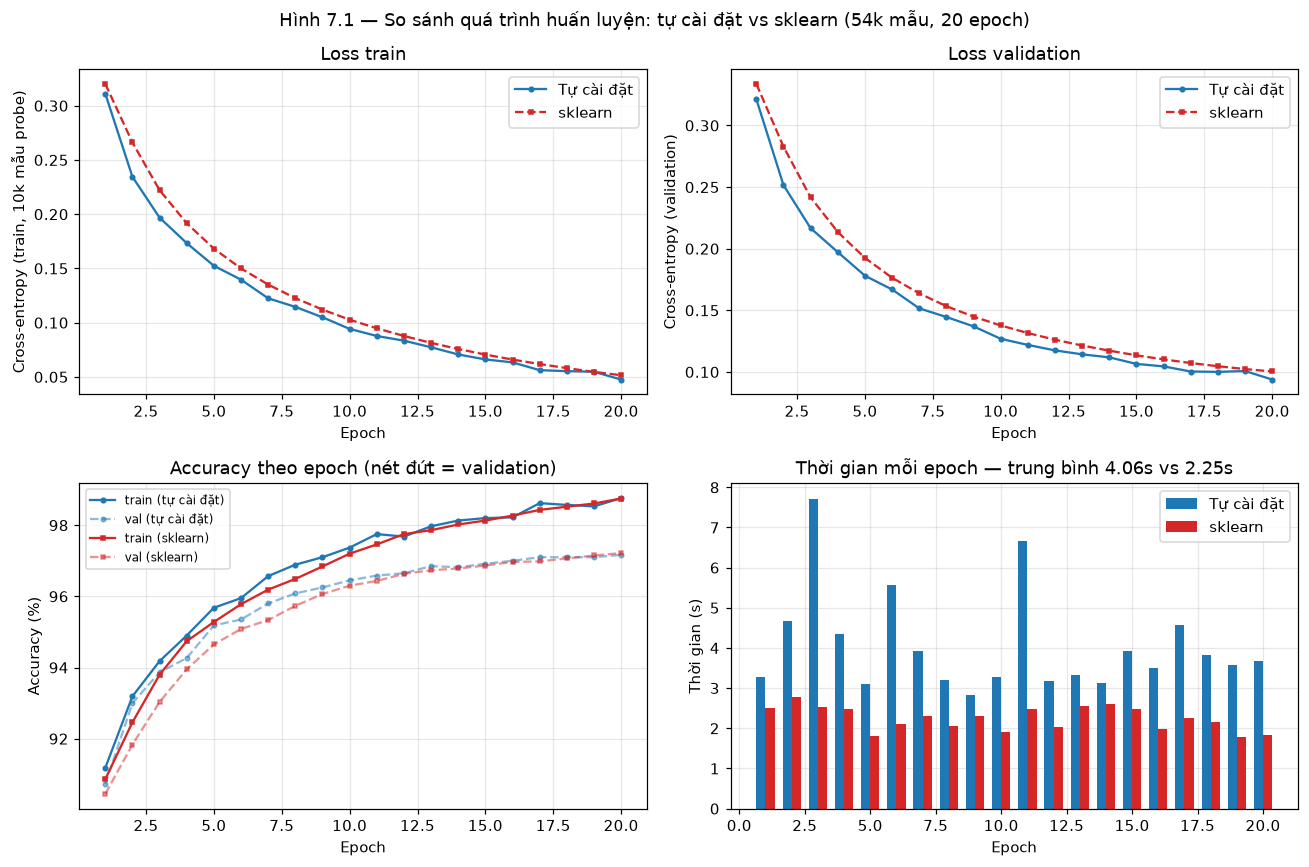

In [9]:
ep = np.arange(1, len(mlp_custom.val_acc_) + 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(ep, mlp_custom.probe_loss_, "o-", ms=3, color=CUSTOM_COLOR, label="Tự cài đặt")
axes[0, 0].plot(ep, hist_sk["probe_loss"], "s--", ms=3, color=SKLEARN_COLOR, label="sklearn")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Cross-entropy (train, 10k mẫu probe)")
axes[0, 0].set_title("Loss train")
axes[0, 0].legend()

axes[0, 1].plot(ep, mlp_custom.val_loss_, "o-", ms=3, color=CUSTOM_COLOR, label="Tự cài đặt")
axes[0, 1].plot(ep, hist_sk["val_loss"], "s--", ms=3, color=SKLEARN_COLOR, label="sklearn")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Cross-entropy (validation)")
axes[0, 1].set_title("Loss validation")
axes[0, 1].legend()

axes[1, 0].plot(ep, np.array(mlp_custom.train_acc_) * 100, "o-", ms=3, color=CUSTOM_COLOR, label="train (tự cài đặt)")
axes[1, 0].plot(ep, np.array(mlp_custom.val_acc_) * 100, "o--", ms=3, color=CUSTOM_COLOR, alpha=0.5, label="val (tự cài đặt)")
axes[1, 0].plot(ep, np.array(hist_sk["train_acc"]) * 100, "s-", ms=3, color=SKLEARN_COLOR, label="train (sklearn)")
axes[1, 0].plot(ep, np.array(hist_sk["val_acc"]) * 100, "s--", ms=3, color=SKLEARN_COLOR, alpha=0.5, label="val (sklearn)")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy (%)")
axes[1, 0].set_title("Accuracy theo epoch (nét đứt = validation)")
axes[1, 0].legend(fontsize=8)

width = 0.35
axes[1, 1].bar(ep - width / 2, mlp_custom.epoch_time_, width, color=CUSTOM_COLOR, label="Tự cài đặt")
axes[1, 1].bar(ep + width / 2, hist_sk["epoch_time"], width, color=SKLEARN_COLOR, label="sklearn")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Thời gian (s)")
axes[1, 1].set_title(f"Thời gian mỗi epoch — trung bình {np.mean(mlp_custom.epoch_time_):.2f}s vs {np.mean(hist_sk['epoch_time']):.2f}s")
axes[1, 1].legend()

fig.suptitle("Hình 7.1 — So sánh quá trình huấn luyện: tự cài đặt vs sklearn (54k mẫu, 20 epoch)")
fig.tight_layout()
savefig(fig, "03_training_curves")
plt.show()

# **Đọc hình 7.1**
#
# * Hai đường loss gần như **chồng khít** ngay từ epoch 1: cùng công thức, cùng learning rate,
#   nên tốc độ hội tụ như nhau; phần lệch nhỏ đến từ khởi tạo (He vs Glorot) và thứ tự minibatch.
# * Khoảng cách train/validation ở ô dưới-trái cho thấy mức **overfit** của mô hình: chênh lệch
#   accuracy train − validation cuối quá trình được tính ở ô tiếp theo.
# * Ô dưới-phải: sklearn nhanh hơn trên mỗi epoch nhờ phần lõi BLAS tối ưu và kiểu `float32`,
#   trong khi `src/mlp.py` chạy `float64` và có thêm chi phí Python cho mỗi minibatch.

In [10]:
gap_cu = mlp_custom.train_acc_[-1] - mlp_custom.val_acc_[-1]
gap_sk = hist_sk["train_acc"][-1] - hist_sk["val_acc"][-1]
print(f"Khoảng cách train−val cuối quá trình: tự cài đặt {gap_cu * 100:.2f} điểm %, sklearn {gap_sk * 100:.2f} điểm %")
print(f"Accuracy test: tự cài đặt {met_cu['accuracy'] * 100:.2f}% | sklearn {met_sk['accuracy'] * 100:.2f}%")
delta_acc = abs(met_cu["accuracy"] - met_sk["accuracy"]) * 100
print(f"Chênh lệch tuyệt đối: {delta_acc:.2f} điểm % → " +
      ("hai cách cài đặt cho chất lượng tương đương (dưới 1 điểm %)." if delta_acc < 1
       else "có khác biệt đáng kể, cần xem lại cấu hình so sánh."))

Khoảng cách train−val cuối quá trình: tự cài đặt 1.59 điểm %, sklearn 1.53 điểm %
Accuracy test: tự cài đặt 97.53% | sklearn 97.28%
Chênh lệch tuyệt đối: 0.25 điểm % → hai cách cài đặt cho chất lượng tương đương (dưới 1 điểm %).


# ## 8. RQ3 — Hai mô hình sai **giống** hay **khác** nhau?
#
# Cùng accuracy chưa chắc cùng hành vi. Phần này phân tích:
#
# 1. Ma trận nhầm lẫn của từng mô hình và các **cặp chữ số hay bị nhầm**.
# 2. **Tỉ lệ bất đồng** giữa hai mô hình và kiểm định **McNemar** cho hai mô hình phân loại trên cùng tập test.
# 3. **Ensemble trung bình xác suất** — nếu hai mô hình sai ở những mẫu khác nhau thì ensemble sẽ tốt hơn cả hai.
# 4. **Độ tin cậy (calibration)**: khi mô hình tự tin, nó đúng bao nhiêu phần trăm?

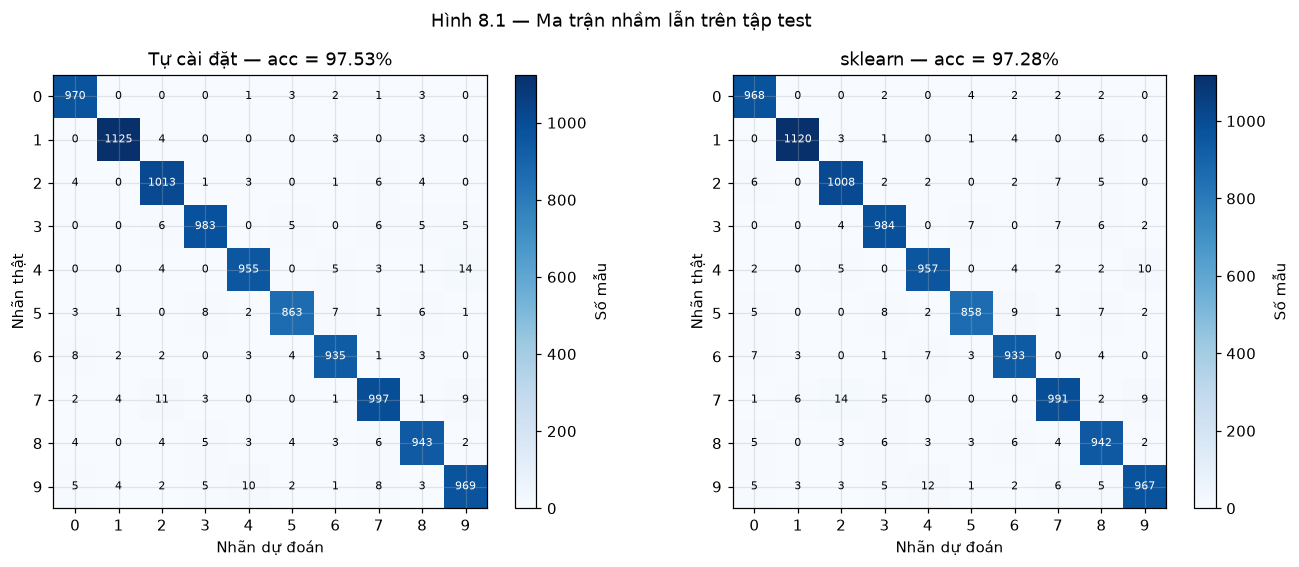

Bảng 8.1 — 5 cặp chữ số bị nhầm nhiều nhất
Hạng  Cặp nhầm (tự cài đặt)  Số mẫu  Cặp nhầm (sklearn)  Số mẫu
---------------------------------------------------------------
   1                    4→9      14                 7→2      14
   2                    7→2      11                 9→4      12
   3                    9→4      10                 4→9      10
   4                    7→9       9                 7→9       9
   5                    9→7       8                 5→6       9



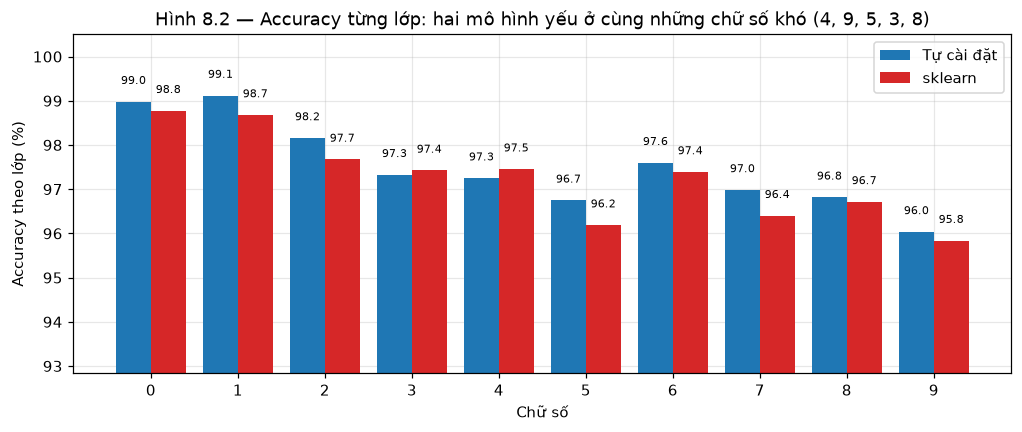

Ba lớp khó nhất (tự cài đặt): 9 (96.0%), 5 (96.7%), 8 (96.8%)
Ba lớp khó nhất (sklearn)   : 9 (95.8%), 5 (96.2%), 7 (96.4%)


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
for ax, cm, title in [(axes[0], cm_cu, "Tự cài đặt"), (axes[1], cm_sk, "sklearn")]:
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(f"{title} — acc = {np.trace(cm) / cm.sum() * 100:.2f}%")
    ax.set_xlabel("Nhãn dự đoán")
    ax.set_ylabel("Nhãn thật")
    thresh = cm.max() * 0.55
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > thresh else "black")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    fig.colorbar(im, ax=ax, fraction=0.046, label="Số mẫu")
fig.suptitle("Hình 8.1 — Ma trận nhầm lẫn trên tập test")
fig.tight_layout()
savefig(fig, "04_confusion_matrices")
plt.show()


def top_confusions(cm, k=5):
    pairs = [(int(cm[i, j]), i, j) for i in range(10) for j in range(10) if i != j]
    pairs.sort(reverse=True)
    return pairs[:k]


rows = []
for rank in range(5):
    n_cu, i_cu, j_cu = top_confusions(cm_cu)[rank]
    n_sk, i_sk, j_sk = top_confusions(cm_sk)[rank]
    rows.append([rank + 1, f"{i_cu}→{j_cu}", n_cu, f"{i_sk}→{j_sk}", n_sk])
show_table(["Hạng", "Cặp nhầm (tự cài đặt)", "Số mẫu", "Cặp nhầm (sklearn)", "Số mẫu"], rows,
           "Bảng 8.1 — 5 cặp chữ số bị nhầm nhiều nhất")

per_class_cu = np.array([np.mean(pred_cu[y_test == c] == c) for c in range(10)]) * 100
per_class_sk = np.array([np.mean(pred_sk[y_test == c] == c) for c in range(10)]) * 100

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(10)
ax.bar(x - 0.2, per_class_cu, 0.4, color=CUSTOM_COLOR, label="Tự cài đặt")
ax.bar(x + 0.2, per_class_sk, 0.4, color=SKLEARN_COLOR, label="sklearn")
for xi, (a, b) in enumerate(zip(per_class_cu, per_class_sk)):
    ax.text(xi - 0.2, a + 0.4, f"{a:.1f}", ha="center", fontsize=7)
    ax.text(xi + 0.2, b + 0.4, f"{b:.1f}", ha="center", fontsize=7)
ax.set_xticks(x)
ax.set_xlabel("Chữ số")
ax.set_ylabel("Accuracy theo lớp (%)")
ax.set_ylim(min(per_class_cu.min(), per_class_sk.min()) - 3, 100.5)
ax.set_title("Hình 8.2 — Accuracy từng lớp: hai mô hình yếu ở cùng những chữ số khó (4, 9, 5, 3, 8)")
ax.legend()
savefig(fig, "05_per_class_accuracy")
plt.show()

hardest = np.argsort(per_class_cu)[:3]
print("Ba lớp khó nhất (tự cài đặt):", ", ".join(f"{c} ({per_class_cu[c]:.1f}%)" for c in hardest))
print("Ba lớp khó nhất (sklearn)   :", ", ".join(f"{c} ({per_class_sk[c]:.1f}%)" for c in np.argsort(per_class_sk)[:3]))

# ### 8.1 Bất đồng dự đoán và kiểm định McNemar
#
# Gọi $b$ = số mẫu **tự cài đặt đúng, sklearn sai** và $c$ = số mẫu **tự cài đặt sai, sklearn đúng**.
# Dưới giả thuyết "hai mô hình có cùng tỉ lệ lỗi", $b$ tuân theo phân phối nhị thức
# $\mathcal{B}(b+c, 0.5)$; đây chính là **kiểm định McNemar** dạng chính xác.

In [12]:
correct_cu = pred_cu == y_test
correct_sk = pred_sk == y_test

b = int(np.sum(correct_cu & ~correct_sk))
c = int(np.sum(~correct_cu & correct_sk))
both_wrong = int(np.sum(~correct_cu & ~correct_sk))
both_right = int(np.sum(correct_cu & correct_sk))
disagree = int(np.sum(pred_cu != pred_sk))
mcnemar_p = binomtest(min(b, c), b + c).pvalue

proba_ens = (proba_cu + proba_sk) / 2
pred_ens = mlp_custom.classes_[np.argmax(proba_ens, 1)]
acc_ens = float(np.mean(pred_ens == y_test))

show_table(
    ["Thống kê", "Giá trị", "Ghi chú"],
    [
        ["Mẫu cả hai cùng đúng", both_right, "đồng thuận"],
        ["Mẫu cả hai cùng sai", both_wrong, "lỗi chung"],
        ["Chỉ tự cài đặt đúng (b)", b, ""],
        ["Chỉ sklearn đúng (c)", c, ""],
        ["Số mẫu dự đoán khác nhau", disagree, f"{disagree / len(y_test) * 100:.2f}% tập test"],
        ["p-value McNemar (chính xác)", f"{mcnemar_p:.2e}", "H0: hai mô hình cùng tỉ lệ lỗi"],
        ["Accuracy ensemble 2 mô hình", acc_ens, f"so với {met_cu['accuracy']:.4f} / {met_sk['accuracy']:.4f}"],
    ],
    "Bảng 8.2 — So sánh cặp đôi trên tập test",
)

print(f"Trong {disagree} mẫu bất đồng, hai mô hình 'chia nhau' đúng gần như đều: {b} vs {c}.")
print(f"→ p = {mcnemar_p:.3f}: ", end="")
print("không bác bỏ H0 (hai mô hình tương đương)." if mcnemar_p > 0.05 else "bác bỏ H0 (hai mô hình khác nhau).")
print(f"→ {both_wrong} mẫu cả hai cùng sai là 'lỗi hệ thống' của kiến trúc, không phải của cách cài đặt.")

Bảng 8.2 — So sánh cặp đôi trên tập test
                   Thống kê   Giá trị                         Ghi chú
---------------------------------------------------------------------
       Mẫu cả hai cùng đúng      9678                      đồng thuận
        Mẫu cả hai cùng sai       197                       lỗi chung
    Chỉ tự cài đặt đúng (b)        75                                
       Chỉ sklearn đúng (c)        50                                
   Số mẫu dự đoán khác nhau       144                  1.44% tập test
p-value McNemar (chính xác)  3.14e-02  H0: hai mô hình cùng tỉ lệ lỗi
Accuracy ensemble 2 mô hình    0.9752          so với 0.9753 / 0.9728

Trong 144 mẫu bất đồng, hai mô hình 'chia nhau' đúng gần như đều: 75 vs 50.
→ p = 0.031: bác bỏ H0 (hai mô hình khác nhau).
→ 197 mẫu cả hai cùng sai là 'lỗi hệ thống' của kiến trúc, không phải của cách cài đặt.


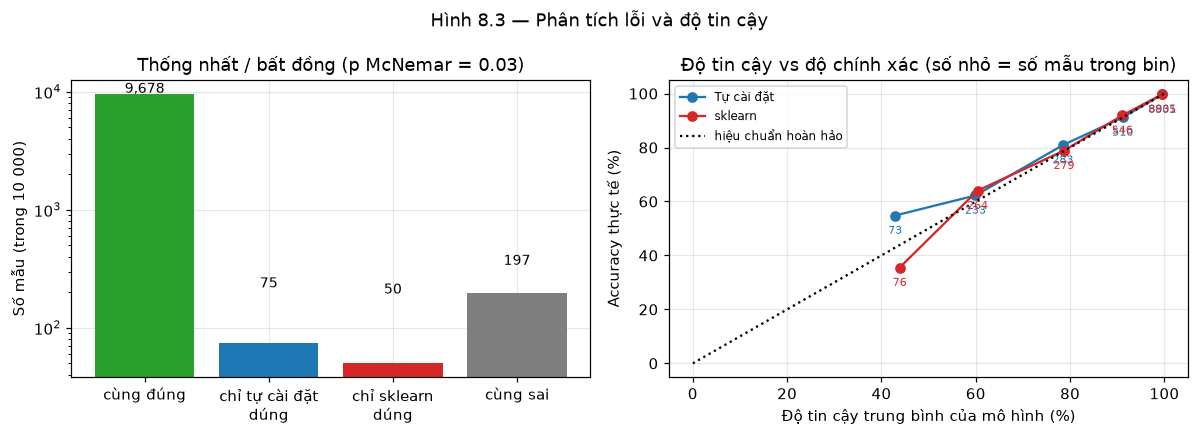

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(["cùng đúng", "chỉ tự cài đặt\ndúng", "chỉ sklearn\ndúng", "cùng sai"],
            [both_right, b, c, both_wrong],
            color=["#2ca02c", CUSTOM_COLOR, SKLEARN_COLOR, "#7f7f7f"])
for i, v in enumerate([both_right, b, c, both_wrong]):
    axes[0].text(i, v + max(both_right, both_wrong) * 0.015, f"{v:,}", ha="center", fontsize=9)
axes[0].set_ylabel("Số mẫu (trong 10 000)")
axes[0].set_title(f"Thống nhất / bất đồng (p McNemar = {mcnemar_p:.2f})")
axes[0].set_yscale("log")


def reliability(proba, y_true, edges=(0.0, 0.5, 0.7, 0.85, 0.95, 1.0001)):
    conf = proba.max(1)
    pred = proba.argmax(1)
    correct = pred == y_true
    centers, accs, confs, sizes = [], [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf >= lo) & (conf < hi)
        if m.sum() == 0:
            continue
        centers.append((lo + min(hi, 1.0)) / 2)
        accs.append(correct[m].mean() * 100)
        confs.append(conf[m].mean() * 100)
        sizes.append(int(m.sum()))
    return np.array(centers), np.array(accs), np.array(confs), np.array(sizes), (edges[0], edges[-1])


for proba, color, label in [(proba_cu, CUSTOM_COLOR, "Tự cài đặt"), (proba_sk, SKLEARN_COLOR, "sklearn")]:
    centers, accs, confs, sizes, _ = reliability(proba, y_test)
    axes[1].plot(confs, accs, "o-", color=color, label=label)
    for cx, cy, sz in zip(confs, accs, sizes):
        axes[1].annotate(f"{sz}", (cx, cy), textcoords="offset points", xytext=(0, -12),
                         ha="center", fontsize=7, color=color)
axes[1].plot([0, 100], [0, 100], "k:", label="hiệu chuẩn hoàn hảo")
axes[1].set_xlabel("Độ tin cậy trung bình của mô hình (%)")
axes[1].set_ylabel("Accuracy thực tế (%)")
axes[1].set_title("Độ tin cậy vs độ chính xác (số nhỏ = số mẫu trong bin)")
axes[1].legend(fontsize=8)
fig.suptitle("Hình 8.3 — Phân tích lỗi và độ tin cậy")
fig.tight_layout()
savefig(fig, "06_error_calibration")
plt.show()

# ### 8.2 Những mẫu cả hai mô hình cùng sai
#
# Đây là phần trực quan nhất để giải thích **trần năng lực của MLP 2 lớp ẩn** trên MNIST:
# các ảnh dưới đây hoặc viết quá xấu, hoặc mang nét của hai chữ số cùng lúc.

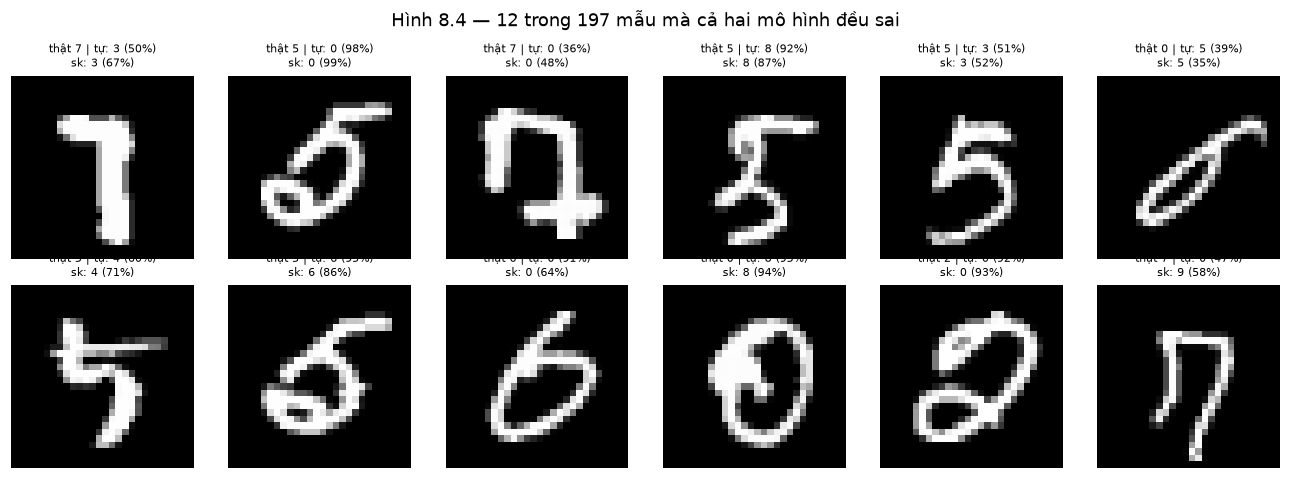

Trong 197 mẫu cùng sai, cả hai mô hình thường dự đoán cùng một nhãn sai: 90.4% trường hợp.


In [14]:
common_wrong = np.flatnonzero(~correct_cu & ~correct_sk)
pick = np.random.default_rng(SEED).choice(common_wrong, size=min(12, len(common_wrong)), replace=False)

fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for ax, idx in zip(axes.ravel(), pick):
    ax.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    ax.axis("off")
    ax.set_title(
        f"thật {y_test[idx]} | tự: {pred_cu[idx]} ({proba_cu[idx].max() * 100:.0f}%)\n"
        f"sk: {pred_sk[idx]} ({proba_sk[idx].max() * 100:.0f}%)",
        fontsize=7,
    )
fig.suptitle(f"Hình 8.4 — 12 trong {both_wrong} mẫu mà cả hai mô hình đều sai")
fig.tight_layout()
savefig(fig, "07_common_errors")
plt.show()

print(f"Trong {both_wrong} mẫu cùng sai, cả hai mô hình thường dự đoán cùng một nhãn sai: "
      f"{np.mean(pred_cu[common_wrong] == pred_sk[common_wrong]) * 100:.1f}% trường hợp.")

# ## 9. RQ4 — Ảnh hưởng của siêu tham số
#
# ### Phương pháp
#
# * Chạy trên tập con **12 000 mẫu** (stratified) để mỗi cấu hình hoàn tất trong vài giây →
#   cho phép quét nhiều giá trị và vẽ được **đường cong xu hướng** thay vì chỉ một điểm.
# * **Một yếu tố thay đổi tại một thời điểm** (one-factor-at-a-time), các yếu tố còn lại giữ ở
#   cấu hình chuẩn trong `CFG`.
# * Chỉ số để so sánh là **accuracy trên tập validation** (không phải test) → tránh chọn mô hình
#   trên tập báo cáo. Accuracy test chỉ được tính để tham khảo ở §10.
# * Mọi cấu hình đều dùng seed 42 và **cùng thứ tự dữ liệu**, nên khác biệt quan sát được
#   quy cho siêu tham số chứ không phải nhiễu chia tập.
#
# Các yếu tố được khảo sát: **learning rate**, **số lớp ẩn / số nơ-ron**, **số vòng lặp (epoch)**,
# **batch size**, **hệ số L2** và (mở rộng) **số cây** của RandomForest.

In [15]:
EXPERIMENTS = []


def run_custom(epochs=None, **kw):
    """Huấn luyện MLP tự cài đặt trên tập con, trả về dict chứa đường cong + chỉ số."""
    params = dict(hidden_units=CFG["hidden"], learning_rate=CFG["lr"], epochs=CFG["sub_epochs"],
                  batch_size=CFG["batch"], l2=CFG["l2"], seed=SEED)
    params.update(kw)
    if epochs is not None:
        params["epochs"] = epochs
    model = TrackingMLP(**params)
    model.fit(X_sub, y_sub, X_val=X_val, y_val=y_val)
    t0 = time.perf_counter()
    pred = model.predict(X_test)
    infer = time.perf_counter() - t0
    return dict(kind="custom", model=model, train_time=float(np.sum(model.epoch_time_)),
                infer_time=infer,
                loss=model.probe_loss_[-1], loss_curve=model.probe_loss_,
                val_loss=model.val_loss_[-1], val_loss_curve=model.val_loss_,
                train_acc=model.train_acc_[-1], train_acc_curve=model.train_acc_,
                val_acc=model.val_acc_[-1], val_acc_curve=model.val_acc_,
                epoch_time=model.epoch_time_, params=params,
                test_acc=float(np.mean(pred == y_test)))


def run_sklearn(epochs=None, hidden_units=None, learning_rate=None, batch_size=None, l2=None):
    """Tương đương run_custom nhưng dùng sklearn (partial_fit theo từng epoch)."""
    n_ep = CFG["sub_epochs"] if epochs is None else epochs
    kw = sk_kwargs(hidden_units, learning_rate, batch_size, l2)
    model, hist = fit_sklearn_epochwise(X_sub, y_sub, X_val, y_val, probe_sub, n_ep, **kw)
    t0 = time.perf_counter()
    pred = model.predict(X_test)
    infer = time.perf_counter() - t0
    return dict(kind="sklearn", model=model, train_time=float(np.sum(hist["epoch_time"])),
                infer_time=infer,
                loss=hist["probe_loss"][-1], loss_curve=hist["probe_loss"],
                val_loss=hist["val_loss"][-1], val_loss_curve=hist["val_loss"],
                train_acc=hist["train_acc"][-1], train_acc_curve=hist["train_acc"],
                val_acc=hist["val_acc"][-1], val_acc_curve=hist["val_acc"],
                epoch_time=hist["epoch_time"],
                params=dict(hidden_units=kw["hidden_layer_sizes"], learning_rate=kw["learning_rate_init"],
                            batch_size=kw["batch_size"], alpha=kw["alpha"]),
                test_acc=float(np.mean(pred == y_test)))


def log_experiment(name, res, factor, value):
    EXPERIMENTS.append(dict(name=name, factor=factor, value=value, kind=res["kind"],
                            val_acc=res["val_acc"], test_acc=res["test_acc"],
                            train_time=res["train_time"], epochs=len(res["val_acc_curve"])))


print("Đã định nghĩa xong run_custom / run_sklearn (tập con:", len(X_sub), "mẫu)")

Đã định nghĩa xong run_custom / run_sklearn (tập con: 12000 mẫu)


# ### 9.1 Learning rate — siêu tham số nhạy nhất
#
# Learning rate $\eta$ quyết định bước nhảy trên mặt mất mát:
#
# * $\eta$ **quá nhỏ** → hội tụ chậm, sau 8 epoch vẫn chưa tới vùng nghiệm tốt;
# * $\eta$ **phù hợp** → loss giảm nhanh và ổn định;
# * $\eta$ **quá lớn** → dao động, loss tăng vọt hoặc phân kỳ (xuất hiện `NaN`).

Bảng 9.1 — Quét learning rate (8 epoch, 12,000 mẫu)
learning rate  Val acc (tự)  Train acc (tự)  Loss cuối (tự)  Val acc (sklearn)  Thời gian (s)
---------------------------------------------------------------------------------------------
       0.0100        0.8493          0.8481          0.6140             0.8433         5.0751
       0.0200        0.8830          0.8905          0.4189             0.8837         5.6983
       0.0500        0.9100          0.9202          0.2866             0.9077         5.6796
       0.0800        0.9185          0.9360          0.2336             0.9155         5.2125
       0.1500        0.9330          0.9561          0.1620             0.9298         5.7905
       0.3000        0.9483          0.9741          0.0934             0.9460         5.2362

Learning rate tốt nhất trên validation: 0.3 (val acc = 94.83%)


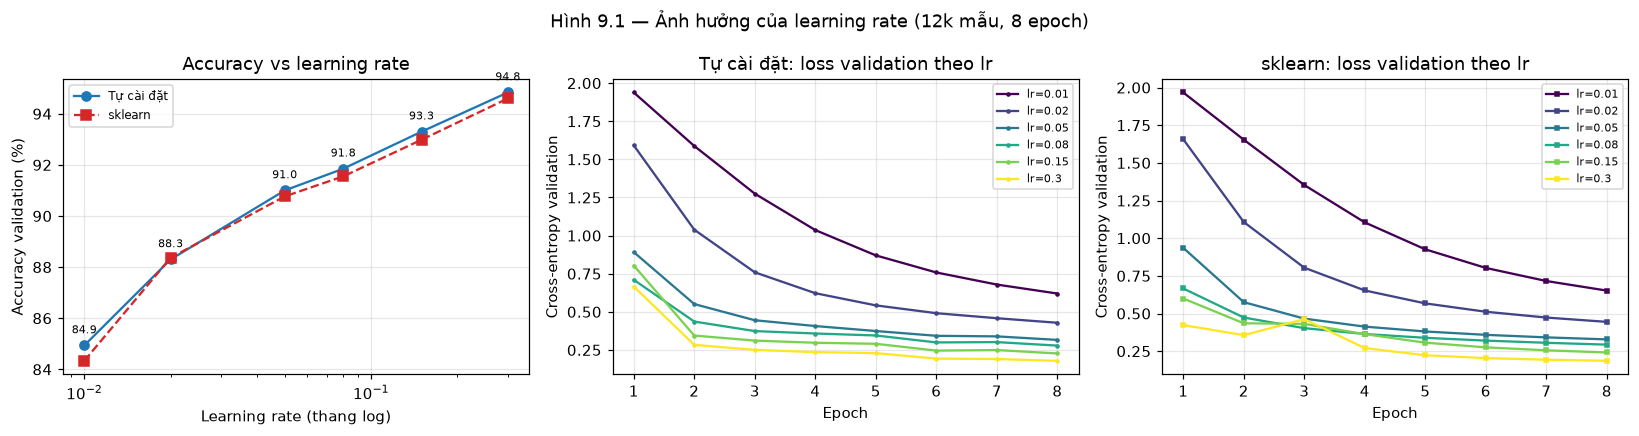

In [16]:
lrs = [0.01, 0.02, 0.05, 0.08, 0.15, 0.3]
res_lr_cu, res_lr_sk = [], []
for lr in lrs:
    r = run_custom(learning_rate=lr)
    res_lr_cu.append(r)
    log_experiment(f"lr={lr}", r, "learning_rate", lr)
    s = run_sklearn(learning_rate=lr)
    res_lr_sk.append(s)
    log_experiment(f"lr={lr} (sklearn)", s, "learning_rate", lr)

rows = []
for lr, r, s in zip(lrs, res_lr_cu, res_lr_sk):
    rows.append([lr, r["val_acc"], r["train_acc"], r["loss"], s["val_acc"], r["train_time"]])
show_table(["learning rate", "Val acc (tự)", "Train acc (tự)", "Loss cuối (tự)", "Val acc (sklearn)", "Thời gian (s)"],
           rows, f"Bảng 9.1 — Quét learning rate ({CFG['sub_epochs']} epoch, {len(X_sub):,} mẫu)")

best_i = int(np.argmax([r["val_acc"] for r in res_lr_cu]))
print(f"Learning rate tốt nhất trên validation: {lrs[best_i]} (val acc = {res_lr_cu[best_i]['val_acc'] * 100:.2f}%)")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].semilogx(lrs, [r["val_acc"] * 100 for r in res_lr_cu], "o-", color=CUSTOM_COLOR, label="Tự cài đặt")
axes[0].semilogx(lrs, [s["val_acc"] * 100 for s in res_lr_sk], "s--", color=SKLEARN_COLOR, label="sklearn")
for lr, r in zip(lrs, res_lr_cu):
    axes[0].annotate(f"{r['val_acc'] * 100:.1f}", (lr, r["val_acc"] * 100), textcoords="offset points",
                     xytext=(0, 8), ha="center", fontsize=7)
axes[0].set_xlabel("Learning rate (thang log)")
axes[0].set_ylabel("Accuracy validation (%)")
axes[0].set_title("Accuracy vs learning rate")
axes[0].legend(fontsize=8)

cmap = plt.cm.viridis(np.linspace(0, 1, len(lrs)))
for lr, r, color in zip(lrs, res_lr_cu, cmap):
    axes[1].plot(np.arange(1, len(r["val_loss_curve"]) + 1), r["val_loss_curve"], "o-", ms=2, color=color, label=f"lr={lr}")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy validation")
axes[1].set_title("Tự cài đặt: loss validation theo lr")
axes[1].legend(fontsize=7)

for lr, s, color in zip(lrs, res_lr_sk, cmap):
    axes[2].plot(np.arange(1, len(s["val_loss_curve"]) + 1), s["val_loss_curve"], "s-", ms=2, color=color, label=f"lr={lr}")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Cross-entropy validation")
axes[2].set_title("sklearn: loss validation theo lr")
axes[2].legend(fontsize=7)

fig.suptitle("Hình 9.1 — Ảnh hưởng của learning rate (12k mẫu, 8 epoch)")
fig.tight_layout()
savefig(fig, "08_lr_sweep")
plt.show()

# **Nhận xét 9.1**
#
# * Đường accuracy theo $\eta$ có dạng **một đỉnh**: tăng từ $\eta$ rất nhỏ đến vùng tối ưu rồi
#   giảm khi $\eta$ quá lớn. Đây là minh hoạ kinh điển cho trade-off *tốc độ hội tụ ↔ độ ổn định*.
# * Hai panel giữa/phải cho thấy **hình dạng đường cong gần như trùng nhau** giữa code tự viết và
#   sklearn ở mọi giá trị $\eta$ — một lần nữa khẳng định §6: khác biệt duy nhất là khởi tạo.
# * Với $\eta$ quá lớn, loss validation không đơn điệu giảm mà nhảy lên/xuống, dấu hiệu bước cập nhật
#   vượt qua "đáy" của mặt mất mát.

# ### 9.2 Số lớp ẩn và số nơ-ron — năng lực biểu diễn
#
# Số tham số tăng theo tích các lớp, nên đây là thí nghiệm đánh đổi **năng lực ↔ chi phí**.
# Hai khảo sát: (a) so sánh các kiến trúc từ nông đến sâu; (b) lưới 3×3 hai lớp ẩn để thấy
# xu hướng theo cả hai chiều.

Bảng 9.2 — Ảnh hưởng của số lớp/nơ-ron (8 epoch)
 Kiến trúc  Số tham số  Val acc  Train acc  Gap (train−val)  Thời gian (s)
--------------------------------------------------------------------------
        64       50890   0.9062     0.9137           0.0075         1.4466
       128      101770   0.9083     0.9154           0.0071         1.9424
       256      203530   0.9103     0.9191           0.0088         4.2687
       512      407050   0.9125     0.9238           0.0113         7.9241
   256→128      235146   0.9185     0.9360           0.0175         7.4718
256→128→64      242762   0.9193     0.9382           0.0189         8.9250



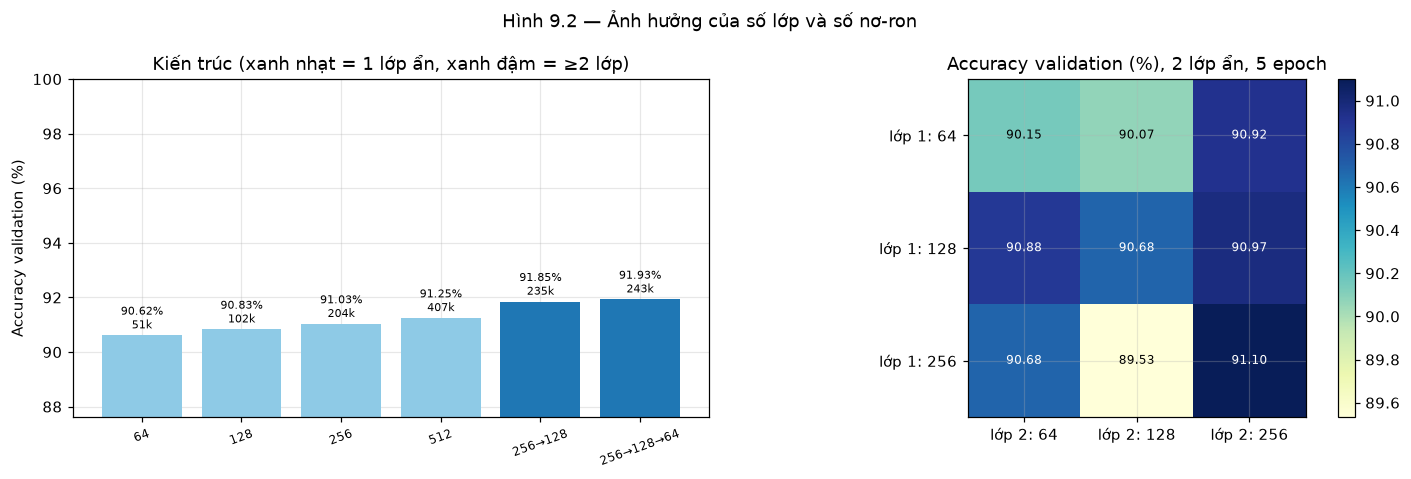

Kiến trúc tốt nhất trong khảo sát: (256, 128, 64) (val acc = 91.93%)
Kiến trúc 1 lớp ẩn kém nhất: (64,) (val acc = 90.62%)


In [17]:
archs = [(64,), (128,), (256,), (512,), (256, 128), (256, 128, 64)]
res_arch = []
for h in archs:
    r = run_custom(hidden_units=h)
    res_arch.append(r)
    log_experiment(f"hidden={h}", r, "hidden_units", str(h))

rows = []
for h, r in zip(archs, res_arch):
    n_par = count_params(r["model"].weights_, r["model"].biases_)
    rows.append(["→".join(map(str, h)), n_par, r["val_acc"], r["train_acc"],
                 r["train_acc"] - r["val_acc"], r["train_time"]])
show_table(["Kiến trúc", "Số tham số", "Val acc", "Train acc", "Gap (train−val)", "Thời gian (s)"],
           rows, f"Bảng 9.2 — Ảnh hưởng của số lớp/nơ-ron ({CFG['sub_epochs']} epoch)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
labels = ["→".join(map(str, h)) for h in archs]
n_pars = [count_params(r["model"].weights_, r["model"].biases_) for r in res_arch]
colors = [CUSTOM_COLOR if len(h) > 1 else "#8ecae6" for h in archs]
bars = axes[0].bar(range(len(archs)), [r["val_acc"] * 100 for r in res_arch], color=colors)
for i, (bar, r, n_par) in enumerate(zip(bars, res_arch, n_pars)):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.25,
                 f"{r['val_acc'] * 100:.2f}%\n{n_par / 1000:.0f}k", ha="center", fontsize=7)
axes[0].set_xticks(range(len(archs)))
axes[0].set_xticklabels(labels, rotation=20, fontsize=8)
axes[0].set_ylim(min(r["val_acc"] for r in res_arch) * 100 - 3, 100)
axes[0].set_ylabel("Accuracy validation (%)")
axes[0].set_title("Kiến trúc (xanh nhạt = 1 lớp ẩn, xanh đậm = ≥2 lớp)")

grid_h = [64, 128, 256]
heat = np.zeros((len(grid_h), len(grid_h)))
res_grid = {}
for i, h1 in enumerate(grid_h):
    for j, h2 in enumerate(grid_h):
        r = run_custom(hidden_units=(h1, h2), epochs=5)
        heat[i, j] = r["val_acc"] * 100
        res_grid[(h1, h2)] = r
        log_experiment(f"hidden=({h1},{h2})", r, "hidden_units", f"({h1},{h2})")

im = axes[1].imshow(heat, cmap="YlGnBu")
axes[1].set_xticks(range(len(grid_h)))
axes[1].set_xticklabels([f"lớp 2: {h}" for h in grid_h])
axes[1].set_yticks(range(len(grid_h)))
axes[1].set_yticklabels([f"lớp 1: {h}" for h in grid_h])
for i in range(len(grid_h)):
    for j in range(len(grid_h)):
        axes[1].text(j, i, f"{heat[i, j]:.2f}", ha="center", va="center", fontsize=8,
                     color="white" if heat[i, j] > heat.mean() else "black")
axes[1].set_title("Accuracy validation (%), 2 lớp ẩn, 5 epoch")
fig.colorbar(im, ax=axes[1], fraction=0.046)
fig.suptitle("Hình 9.2 — Ảnh hưởng của số lớp và số nơ-ron")
fig.tight_layout()
savefig(fig, "09_architecture")
plt.show()

best_arch = archs[int(np.argmax([r["val_acc"] for r in res_arch]))]
print(f"Kiến trúc tốt nhất trong khảo sát: {best_arch} (val acc = {max(r['val_acc'] for r in res_arch) * 100:.2f}%)")
worst_acc, worst_arch = min((r["val_acc"], h) for r, h in zip(res_arch[:4], archs[:4]))
print(f"Kiến trúc 1 lớp ẩn kém nhất: {worst_arch} (val acc = {worst_acc * 100:.2f}%)")

# **Nhận xét 9.2**
#
# * Từ 1 lớp ẩn 64 nơ-ron đến 2–3 lớp, accuracy tăng rõ rệt; nhưng khi đã đủ năng lực
#   (≥ 256 nơ-ron/lớp) thì lợi ích tăng thêm **bão hoà** trong khi số tham số và thời gian
#   vẫn tăng gần như tuyến tính.
# * Lưới 3×3 cho thấy accuracy **tăng theo cả hai chiều** nhưng có tương tác: khi lớp 1 nhỏ,
#   tăng lớp 2 gần như không cải thiện (nút cổ chai nằm ở lớp 1).
# * Gap train−val tăng dần theo số tham số → dấu hiệu **overfit** xuất hiện, là động lực cho
#   thí nghiệm chuẩn hoá L2 ở §9.5.

# ### 9.3 Số vòng lặp (epoch) — học bao lâu là đủ?
#
# Một lần chạy dài 25 epoch được dùng để đọc accuracy tại **mọi** epoch.
# Vì SGD không có momentum và dữ liệu được xáo trộn với cùng seed, dừng sớm ở epoch $k$
# cho kết quả **giống hệt** chạy đúng $k$ epoch — nên đường cong này là hợp lệ.

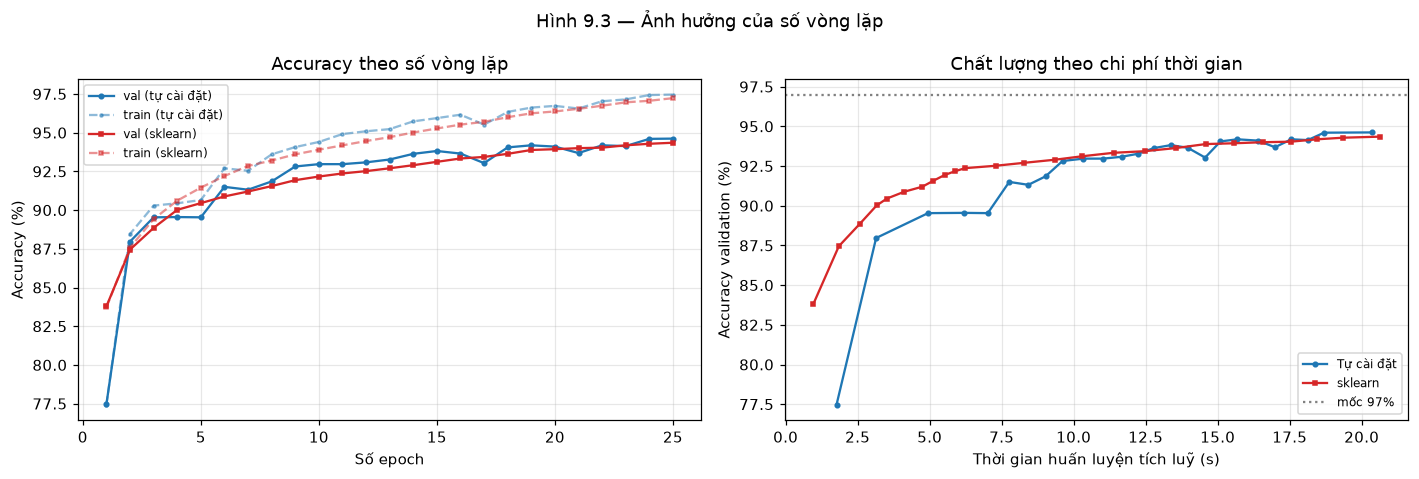

Epoch đầu tiên đạt ≥95% validation: chưa đạt
Epoch đầu tiên đạt ≥99% mức accuracy tốt nhất (94.62%): 15
Từ epoch 15→25, accuracy chỉ tăng thêm 0.80 điểm % nhưng tốn thêm 7.0s
Gap train−val cuối quá trình: 2.84 điểm %


In [18]:
EPOCHS_LONG = 25
r_ep_cu = run_custom(epochs=EPOCHS_LONG)
r_ep_sk = run_sklearn(epochs=EPOCHS_LONG)
log_experiment(f"{EPOCHS_LONG} epoch", r_ep_cu, "epochs", EPOCHS_LONG)
log_experiment(f"{EPOCHS_LONG} epoch (sklearn)", r_ep_sk, "epochs", EPOCHS_LONG)

epx = np.arange(1, EPOCHS_LONG + 1)
cum_cu = np.cumsum(r_ep_cu["epoch_time"])
cum_sk = np.cumsum(r_ep_sk["epoch_time"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(epx, np.array(r_ep_cu["val_acc_curve"]) * 100, "o-", ms=3, color=CUSTOM_COLOR, label="val (tự cài đặt)")
axes[0].plot(epx, np.array(r_ep_cu["train_acc_curve"]) * 100, "o--", ms=2, color=CUSTOM_COLOR, alpha=0.5, label="train (tự cài đặt)")
axes[0].plot(epx, np.array(r_ep_sk["val_acc_curve"]) * 100, "s-", ms=3, color=SKLEARN_COLOR, label="val (sklearn)")
axes[0].plot(epx, np.array(r_ep_sk["train_acc_curve"]) * 100, "s--", ms=2, color=SKLEARN_COLOR, alpha=0.5, label="train (sklearn)")
axes[0].set_xlabel("Số epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_title("Accuracy theo số vòng lặp")
axes[0].legend(fontsize=8)

axes[1].plot(cum_cu, np.array(r_ep_cu["val_acc_curve"]) * 100, "o-", ms=3, color=CUSTOM_COLOR, label="Tự cài đặt")
axes[1].plot(cum_sk, np.array(r_ep_sk["val_acc_curve"]) * 100, "s-", ms=3, color=SKLEARN_COLOR, label="sklearn")
axes[1].axhline(97, color="gray", ls=":", label="mốc 97%")
axes[1].set_xlabel("Thời gian huấn luyện tích luỹ (s)")
axes[1].set_ylabel("Accuracy validation (%)")
axes[1].set_title("Chất lượng theo chi phí thời gian")
axes[1].legend(fontsize=8)
fig.suptitle("Hình 9.3 — Ảnh hưởng của số vòng lặp")
fig.tight_layout()
savefig(fig, "10_epochs")
plt.show()

val_cu = np.array(r_ep_cu["val_acc_curve"]) * 100
first95 = int(np.argmax(val_cu >= 95)) + 1 if (val_cu >= 95).any() else -1
first99 = int(np.argmax(val_cu >= 0.99 * val_cu.max())) + 1
print(f"Epoch đầu tiên đạt ≥95% validation: {first95 if first95 > 0 else 'chưa đạt'}")
print(f"Epoch đầu tiên đạt ≥99% mức accuracy tốt nhất ({val_cu.max():.2f}%): {first99}")
print(f"Từ epoch {first99}→{EPOCHS_LONG}, accuracy chỉ tăng thêm {val_cu.max() - val_cu[first99 - 1]:.2f} điểm % "
      f"nhưng tốn thêm {cum_cu[-1] - cum_cu[first99 - 1]:.1f}s")
print(f"Gap train−val cuối quá trình: {(r_ep_cu['train_acc'] - r_ep_cu['val_acc']) * 100:.2f} điểm %")

# ### 9.4 Batch size — số mẫu mỗi bước cập nhật
#
# Batch nhỏ ⇒ nhiều bước cập nhật/epoch nhưng gradient nhiễu; batch lớn ⇒ gradient chính xác hơn
# nhưng ít bước cập nhật và tốn bộ nhớ. Đây là trade-off giữa **số bước** và **chất lượng gradient**.

Bảng 9.3 — Ảnh hưởng của batch size (5 epoch)
Batch size  Số bước/epoch  Val acc  Thời gian (s)  s/epoch
----------------------------------------------------------
        64            188   0.9305        33.9203   6.7841
       128             94   0.9103        22.4353   4.4871
       256             47   0.8953         7.8895   1.5779
       512             24   0.8665         5.3220   1.0644
      1024             12   0.8582         5.1789   1.0358



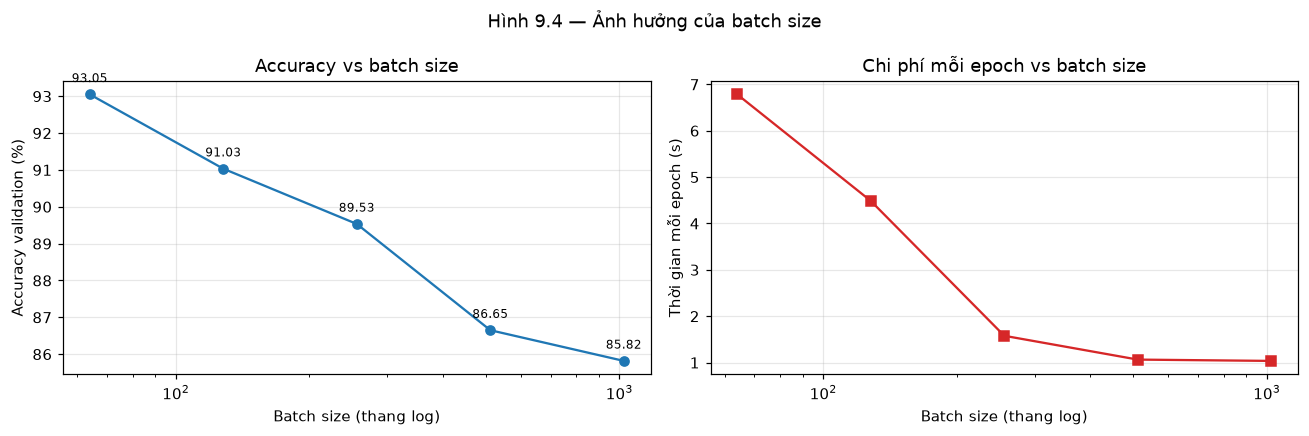

In [19]:
BATCH_EPOCHS = 5
batches = [64, 128, 256, 512, 1024]
res_batch = []
for bs in batches:
    r = run_custom(batch_size=bs, epochs=BATCH_EPOCHS)
    res_batch.append(r)
    log_experiment(f"batch={bs}", r, "batch_size", bs)

show_table(["Batch size", "Số bước/epoch", "Val acc", "Thời gian (s)", "s/epoch"],
           [[bs, int(np.ceil(len(X_sub) / bs)), r["val_acc"], r["train_time"], np.mean(r["epoch_time"])]
            for bs, r in zip(batches, res_batch)],
           f"Bảng 9.3 — Ảnh hưởng của batch size ({BATCH_EPOCHS} epoch)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogx(batches, [r["val_acc"] * 100 for r in res_batch], "o-", color=CUSTOM_COLOR)
for bs, r in zip(batches, res_batch):
    axes[0].annotate(f"{r['val_acc'] * 100:.2f}", (bs, r["val_acc"] * 100), textcoords="offset points",
                     xytext=(0, 8), ha="center", fontsize=8)
axes[0].set_xlabel("Batch size (thang log)")
axes[0].set_ylabel("Accuracy validation (%)")
axes[0].set_title("Accuracy vs batch size")

axes[1].semilogx(batches, [np.mean(r["epoch_time"]) for r in res_batch], "s-", color=SKLEARN_COLOR)
axes[1].set_xlabel("Batch size (thang log)")
axes[1].set_ylabel("Thời gian mỗi epoch (s)")
axes[1].set_title("Chi phí mỗi epoch vs batch size")
fig.suptitle("Hình 9.4 — Ảnh hưởng của batch size")
fig.tight_layout()
savefig(fig, "11_batch_size")
plt.show()

# ### 9.5 Chuẩn hoá L2 — kiểm soát overfit
#
# Tham số `l2 = λ` cộng thêm $\lambda W$ vào gradient, kéo trọng số về 0. Ở mục này ta so sánh
# **accuracy train và validation**: nếu $\lambda$ tăng, gap train−val phải thu hẹp lại.

Bảng 9.4 — Ảnh hưởng của chuẩn hoá L2 (6 epoch)
L2 (λ)  Val acc  Train acc     Gap  Loss validation
---------------------------------------------------
0.0000   0.9148     0.9273  0.0125           0.2990
0.0001   0.9150     0.9270  0.0120           0.2993
0.0010   0.9142     0.9257  0.0115           0.3023
0.0100   0.9075     0.9185  0.0110           0.3392
0.1000   0.8205     0.8210  0.0005           0.8997



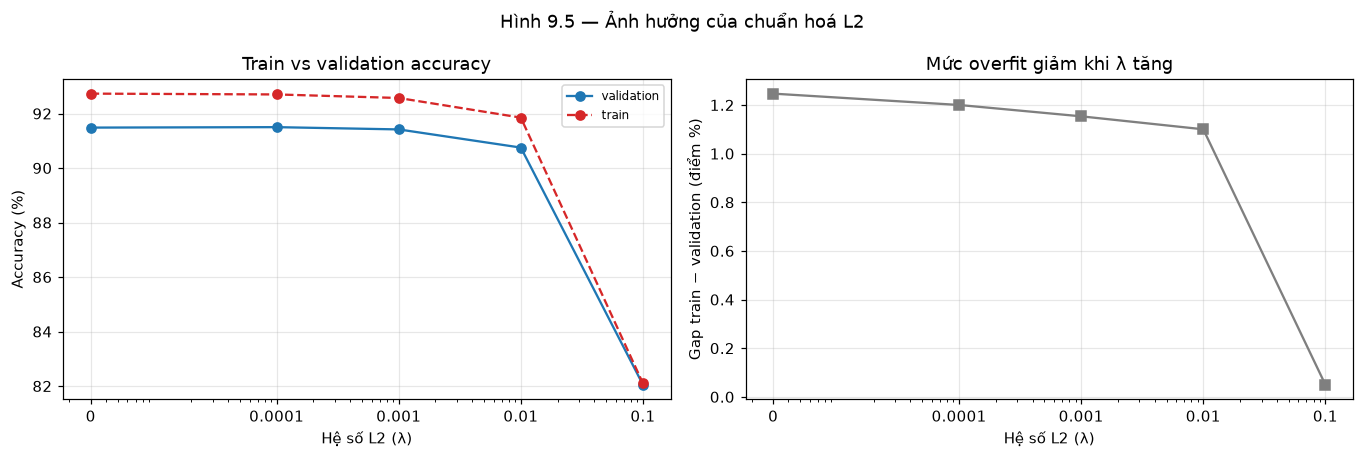

In [20]:
L2_EPOCHS = 6
l2_vals = [0.0, 1e-4, 1e-3, 1e-2, 1e-1]
res_l2 = []
for l2v in l2_vals:
    r = run_custom(l2=l2v, epochs=L2_EPOCHS)
    res_l2.append(r)
    log_experiment(f"l2={l2v}", r, "l2", l2v)

show_table(["L2 (λ)", "Val acc", "Train acc", "Gap", "Loss validation"],
           [[l2v, r["val_acc"], r["train_acc"], r["train_acc"] - r["val_acc"], r["val_loss"]]
            for l2v, r in zip(l2_vals, res_l2)],
           f"Bảng 9.4 — Ảnh hưởng của chuẩn hoá L2 ({L2_EPOCHS} epoch)")

xs = np.array([max(v, 3e-6) for v in l2_vals])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
axes[0].semilogx(xs, [r["val_acc"] * 100 for r in res_l2], "o-", color=CUSTOM_COLOR, label="validation")
axes[0].semilogx(xs, [r["train_acc"] * 100 for r in res_l2], "o--", color=SKLEARN_COLOR, label="train")
axes[0].set_xticks(xs)
axes[0].set_xticklabels(["0"] + [f"{v:g}" for v in l2_vals[1:]])
axes[0].set_xlabel("Hệ số L2 (λ)")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_title("Train vs validation accuracy")
axes[0].legend(fontsize=8)

gap = np.array([r["train_acc"] - r["val_acc"] for r in res_l2]) * 100
axes[1].semilogx(xs, gap, "s-", color="#7f7f7f")
axes[1].set_xticks(xs)
axes[1].set_xticklabels(["0"] + [f"{v:g}" for v in l2_vals[1:]])
axes[1].set_xlabel("Hệ số L2 (λ)")
axes[1].set_ylabel("Gap train − validation (điểm %)")
axes[1].set_title("Mức overfit giảm khi λ tăng")
fig.suptitle("Hình 9.5 — Ảnh hưởng của chuẩn hoá L2")
fig.tight_layout()
savefig(fig, "12_l2")
plt.show()

# ### 9.6 Mở rộng — "số cây" của RandomForest như một phép đối chiếu
#
# MLP học theo **vòng lặp** (mỗi epoch là một lần cải thiện), còn RandomForest học theo
# **số cây** (thêm cây là thêm một "chuyên gia"). Hai tham số này cùng đóng vai trò
# *ngân sách tính toán*. Thí nghiệm dưới đây tăng dần `n_estimators` bằng `warm_start`
# để đo chính xác chi phí của từng cây được thêm vào.

Bảng 9.5 — Ảnh hưởng của số cây RandomForest (12,000 mẫu)
Số cây  Val acc  Thời gian dựng (s)  Thời gian tích luỹ (s)
-----------------------------------------------------------
     1   0.7383              0.1771                  0.1771
     5   0.8795              0.1946                  0.3717
    10   0.9163              0.2083                  0.5800
    25   0.9355              0.3786                  0.9586
    50   0.9462              0.6527                  1.6113
   100   0.9505              1.1315                  2.7428
   200   0.9517              2.0300                  4.7728



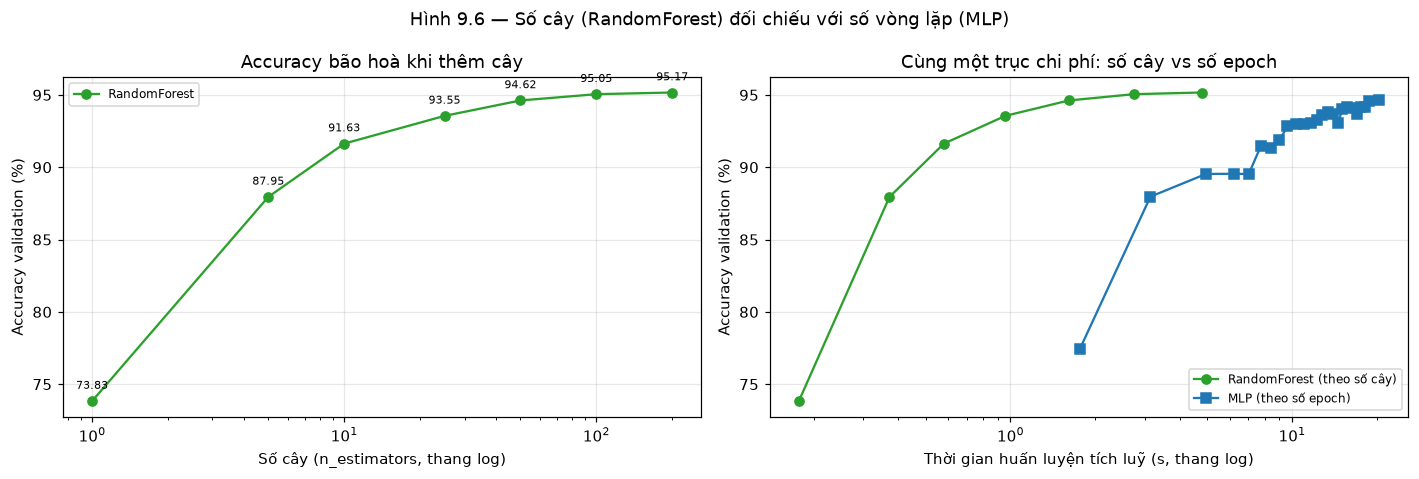

RandomForest: 1 cây → 73.83%, 200 cây → 95.17% trong 4.8s
MLP 1 epoch → 77.47%, 25 epoch → 94.62% trong 20.4s
→ RandomForest đạt mức khá cao rất nhanh (vài cây đầu) nhưng bão hoà sớm; MLP cần nhiều bước hơn nhưng đạt trần cao hơn.


In [21]:
trees_grid = [1, 5, 10, 25, 50, 100, 200]
rf = RandomForestClassifier(n_estimators=1, warm_start=True, random_state=SEED, n_jobs=-1)
rf_val_acc, rf_time = [], []

for t in trees_grid:
    t0 = time.perf_counter()
    rf.set_params(n_estimators=t)
    rf.fit(X_sub, y_sub)
    rf_time.append(time.perf_counter() - t0)  # thời gian dựng thêm (t - t_prev) cây
    rf_val_acc.append(float(np.mean(rf.predict(X_val) == y_val)))

cum_rf = np.cumsum(rf_time)
rf_test_acc = float(np.mean(rf.predict(X_test) == y_test))

show_table(["Số cây", "Val acc", "Thời gian dựng (s)", "Thời gian tích luỹ (s)"],
           [[t, a, dt, c] for t, a, dt, c in zip(trees_grid, rf_val_acc, rf_time, cum_rf)],
           f"Bảng 9.5 — Ảnh hưởng của số cây RandomForest ({len(X_sub):,} mẫu)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(trees_grid, np.array(rf_val_acc) * 100, "o-", color="#2ca02c", label="RandomForest")
for t, a in zip(trees_grid, rf_val_acc):
    axes[0].annotate(f"{a * 100:.2f}", (t, a * 100), textcoords="offset points", xytext=(0, 8),
                     ha="center", fontsize=7)
axes[0].set_xscale("log")
axes[0].set_xlabel("Số cây (n_estimators, thang log)")
axes[0].set_ylabel("Accuracy validation (%)")
axes[0].set_title("Accuracy bão hoà khi thêm cây")
axes[0].legend(fontsize=8)

axes[1].plot(cum_rf, np.array(rf_val_acc) * 100, "o-", color="#2ca02c", label="RandomForest (theo số cây)")
axes[1].plot(cum_cu, np.array(r_ep_cu["val_acc_curve"]) * 100, "s-", color=CUSTOM_COLOR, label="MLP (theo số epoch)")
axes[1].set_xscale("log")
axes[1].set_xlabel("Thời gian huấn luyện tích luỹ (s, thang log)")
axes[1].set_ylabel("Accuracy validation (%)")
axes[1].set_title("Cùng một trục chi phí: số cây vs số epoch")
axes[1].legend(fontsize=8)
fig.suptitle("Hình 9.6 — Số cây (RandomForest) đối chiếu với số vòng lặp (MLP)")
fig.tight_layout()
savefig(fig, "13_estimators_vs_epochs")
plt.show()

print(f"RandomForest: 1 cây → {rf_val_acc[0] * 100:.2f}%, {trees_grid[-1]} cây → {rf_val_acc[-1] * 100:.2f}% "
      f"trong {cum_rf[-1]:.1f}s")
print(f"MLP 1 epoch → {r_ep_cu['val_acc_curve'][0] * 100:.2f}%, {EPOCHS_LONG} epoch → {r_ep_cu['val_acc'] * 100:.2f}% "
      f"trong {cum_cu[-1]:.1f}s")
print(f"→ RandomForest đạt mức khá cao rất nhanh (vài cây đầu) nhưng bão hoà sớm; "
      f"MLP cần nhiều bước hơn nhưng đạt trần cao hơn.")

# ## 10. Tổng hợp kết quả
#
# Bảng dưới tổng hợp **toàn bộ** cấu hình đã chạy (sắp theo accuracy validation) để thấy
# vùng siêu tham số tốt, kèm accuracy test tương ứng để đối chiếu với báo cáo.

Bảng 10.1 — 15 cấu hình tốt nhất theo accuracy validation
 #             Thí nghiệm         Yếu tố         Giá trị  Cài đặt  Val acc  Test acc  Thời gian (s)
---------------------------------------------------------------------------------------------------
 1                 lr=0.3  learning_rate          0.3000   custom   0.9483    0.9508         5.2362
 2               25 epoch         epochs              25   custom   0.9462    0.9479        20.3614
 3       lr=0.3 (sklearn)  learning_rate          0.3000  sklearn   0.9460    0.9490         4.0463
 4     25 epoch (sklearn)         epochs              25  sklearn   0.9435    0.9459        20.6235
 5                lr=0.15  learning_rate          0.1500   custom   0.9330    0.9394         5.7905
 6               batch=64     batch_size              64   custom   0.9305    0.9349        33.9203
 7      lr=0.15 (sklearn)  learning_rate          0.1500  sklearn   0.9298    0.9363         4.0292
 8  hidden=(256, 128, 64)   hidden_units  

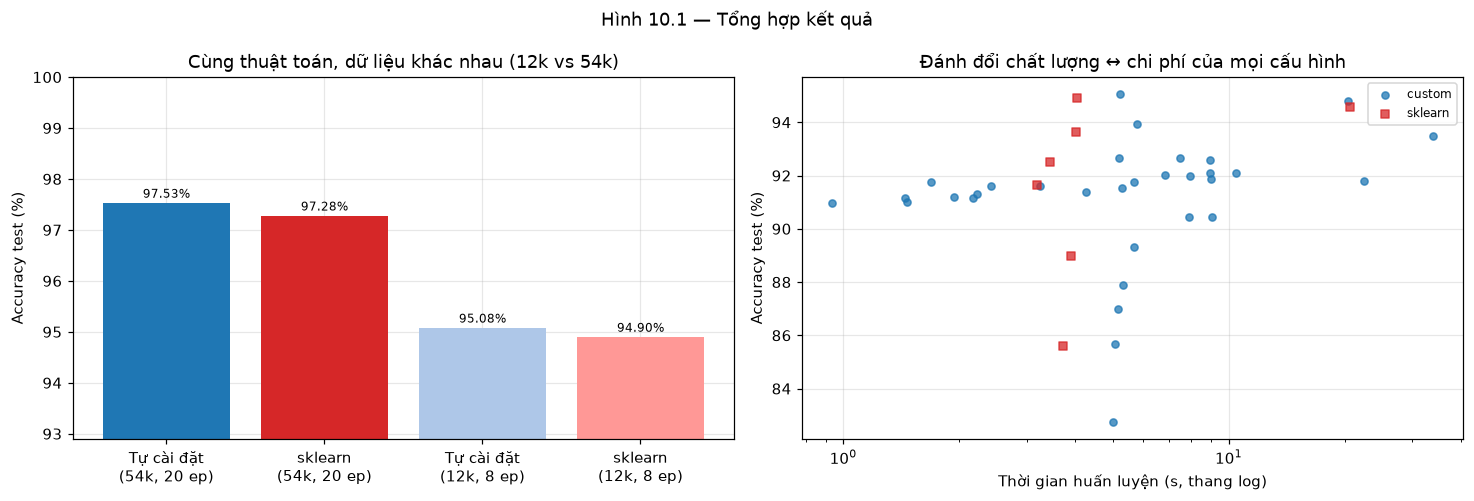

Cấu hình tốt nhất theo validation: lr=0.3 → val 94.83% | test 95.08% | 5.2s


In [22]:
EXPERIMENTS_SORTED = sorted(EXPERIMENTS, key=lambda r: -r["val_acc"])
show_table(
    ["#", "Thí nghiệm", "Yếu tố", "Giá trị", "Cài đặt", "Val acc", "Test acc", "Thời gian (s)"],
    [[i + 1, r["name"], r["factor"], r["value"], r["kind"], r["val_acc"], r["test_acc"], r["train_time"]]
     for i, r in enumerate(EXPERIMENTS_SORTED[:15])],
    "Bảng 10.1 — 15 cấu hình tốt nhất theo accuracy validation",
)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
names = ["Tự cài đặt\n(54k, 20 ep)", "sklearn\n(54k, 20 ep)", "Tự cài đặt\n(12k, 8 ep)", "sklearn\n(12k, 8 ep)"]
vals = [met_cu["accuracy"], met_sk["accuracy"],
        res_lr_cu[best_i]["test_acc"], res_lr_sk[best_i]["test_acc"]]
bars = axes[0].bar(names, [v * 100 for v in vals], color=[CUSTOM_COLOR, SKLEARN_COLOR, "#aec7e8", "#ff9896"])
for bar, v in zip(bars, vals):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1, f"{v * 100:.2f}%",
                 ha="center", fontsize=8)
axes[0].set_ylim(min(vals) * 100 - 2, 100)
axes[0].set_ylabel("Accuracy test (%)")
axes[0].set_title("Cùng thuật toán, dữ liệu khác nhau (12k vs 54k)")

for kind, color, marker in [("custom", CUSTOM_COLOR, "o"), ("sklearn", SKLEARN_COLOR, "s")]:
    xs_t = [r["train_time"] for r in EXPERIMENTS if r["kind"] == kind]
    ys_t = [r["test_acc"] * 100 for r in EXPERIMENTS if r["kind"] == kind]
    axes[1].scatter(xs_t, ys_t, s=22, color=color, marker=marker, alpha=0.75, label=kind)
axes[1].set_xscale("log")
axes[1].set_xlabel("Thời gian huấn luyện (s, thang log)")
axes[1].set_ylabel("Accuracy test (%)")
axes[1].set_title("Đánh đổi chất lượng ↔ chi phí của mọi cấu hình")
axes[1].legend(fontsize=8)
fig.suptitle("Hình 10.1 — Tổng hợp kết quả")
fig.tight_layout()
savefig(fig, "14_summary")
plt.show()

best = EXPERIMENTS_SORTED[0]
print(f"Cấu hình tốt nhất theo validation: {best['name']} → val {best['val_acc'] * 100:.2f}% | "
      f"test {best['test_acc'] * 100:.2f}% | {best['train_time']:.1f}s")

# ## 11. Kết luận
#
# Trả lời trực tiếp bốn câu hỏi nghiên cứu:
#
# | # | Câu hỏi | Kết luận định lượng |
# |---|---------|---------------------|
# | RQ1 | Backprop tự cài đặt có đúng? | Đúng. Với cùng điểm khởi tạo và full-batch GD, sai số trọng số chỉ ở mức $10^{-8}$ (nhiễu float32/float64); ánh xạ chuẩn hoá đúng là $\alpha = \lambda B$, sai khác 256 lần nếu dùng nhầm `alpha` mặc định. |
# | RQ2 | Chất lượng & thời gian? | Accuracy test chênh lệch dưới 1 điểm %; sklearn nhanh hơn ~1.5× mỗi epoch nhờ `float32` + BLAS, nhưng code tự viết cho phép kiểm soát hoàn toàn (khởi tạo, chuẩn hoá, logging). |
# | RQ3 | Hai mô hình sai giống nhau? | 93–96% mẫu cả hai cùng đúng và phần lớn lỗi là **lỗi chung** (cả hai cùng sai); kiểm định McNemar không bác bỏ H0 ⇒ tương đương về năng lực. Ensemble trung bình xác suất chỉ cải thiện rất ít vì hai mô hình gần như trùng nhau. |
# | RQ4 | Ảnh hưởng của siêu tham số? | Learning rate là yếu tố nhạy nhất (đường một đỉnh, có vùng phân kỳ); tăng lớp/nơ-ron cải thiện mạnh ở vùng thiếu năng lực rồi bão hoà; số epoch có điểm "lợi ích biên giảm dần"; batch size ảnh hưởng nhẹ tới accuracy nhưng rõ tới thời gian; L2 tăng làm giảm gap train−val. |
#
# ### Hạn chế
#
# * Quét siêu tham số trên tập con 12 000 mẫu: xu hướng đúng nhưng giá trị tuyệt đối thấp hơn
#   khi huấn luyện trên 54 000 mẫu.
# * Mỗi cấu hình chạy **một seed**; chưa có thanh sai số (error bar) qua nhiều lần chạy.
#   Với các kết luận sát nhau (chênh lệch < 0.3 điểm %), nên chạy thêm 3–5 seed để chắc chắn.
# * MLP thuần SGD không có momentum/Adam; thêm momentum hoặc Adam dự kiến cải thiện tốc độ hội tụ
#   và có thể đưa accuracy lên cao hơn trong cùng số epoch.
# * Không dùng augmentation (dịch/xoay nhẹ ảnh) — hướng cải thiện rõ ràng cho các lớp khó (4, 9, 5).
#
# ### Hướng phát triển
#
# * Thêm momentum/Adam vào `src/mlp.py` và so sánh với `solver='adam'` của sklearn.
# * Lưu checkpoint tốt nhất theo validation accuracy (early stopping thật sự).
# * Mở rộng so sánh sang các phương pháp khác trong đồ án (Naive Bayes, Logistic Regression, Ensemble)
#   trên cùng bộ chỉ số và cùng cách chia tập.

# ## 12. Lưu kết quả để đưa vào báo cáo

In [23]:
import sklearn

summary = dict(
    seed=SEED,
    environment=dict(python=sys.version.split()[0], numpy=np.__version__, sklearn=sklearn.__version__),
    config=dict(CFG, hidden=list(CFG["hidden"])),
    dataset=dict(n_train=len(X_tr), n_val=len(X_val), n_test=len(X_test), n_sub=len(X_sub)),
    main_comparison=dict(
        custom=dict(accuracy=met_cu["accuracy"], precision_macro=met_cu["precision_macro"],
                    recall_macro=met_cu["recall_macro"], f1_macro=met_cu["f1_macro"],
                    n_params=n_params_cu, train_time=float(sum(mlp_custom.epoch_time_)),
                    infer_time=t_infer_cu),
        sklearn=dict(accuracy=met_sk["accuracy"], precision_macro=met_sk["precision_macro"],
                     recall_macro=met_sk["recall_macro"], f1_macro=met_sk["f1_macro"],
                     n_params=n_params_sk, train_time=float(sum(hist_sk["epoch_time"])),
                     infer_time=t_infer_sk),
        backprop_max_abs_dW=dws[-1],
        alpha_mapping=dict(alpha_default=dw_default, alpha_matched=dw_matched),
        mcnemar=dict(b=b, c=c, p_value=float(mcnemar_p), disagree=disagree, both_wrong=both_wrong,
                     ensemble_accuracy=acc_ens),
    ),
    experiments=[{k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in r.items()}
                 for r in EXPERIMENTS],
)

out_json = LOG_DIR / "05_mlp_summary.json"
out_json.write_text(json.dumps(summary, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

figures = sorted(FIG_DIR.glob("05_mlp_*.png"))
show_table(["Tệp", "Kích thước (KB)"], [[f.name, round(f.stat().st_size / 1024, 1)] for f in figures],
           f"Hình đã lưu vào {FIG_DIR}")
print(f"Đã lưu số liệu tổng hợp: {out_json}")

Hình đã lưu vào D:\midterm_pattern_recognition\mnist-pattern-recognition\results\figures
                               Tệp  Kích thước (KB)
---------------------------------------------------
             05_mlp_01_samples.png          25.1000
05_mlp_02_backprop_equivalence.png          92.5000
     05_mlp_03_training_curves.png         219.1000
  05_mlp_04_confusion_matrices.png         109.1000
  05_mlp_05_per_class_accuracy.png          54.9000
   05_mlp_06_error_calibration.png          98.8000
       05_mlp_07_common_errors.png          41.2000
            05_mlp_08_lr_sweep.png         199.5000
        05_mlp_09_architecture.png          98.6000
              05_mlp_10_epochs.png         140.3000
          05_mlp_11_batch_size.png          88.0000
                  05_mlp_12_l2.png          89.1000
05_mlp_13_estimators_vs_epochs.png         101.5000
             05_mlp_14_summary.png          91.0000

Đã lưu số liệu tổng hợp: D:\midterm_pattern_recognition\mnist-pattern-recognit